# OLIST BRAZILLIAN E-COMMERCE ANALYSIS

In [7]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sklearn
import mlxtend
from mlxtend.frequent_patterns import apriori

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge, LinearRegression
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              IsolationForest)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, adjusted_rand_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_SEED = 42
DATA_FOLDER = "datasets"
FIGURE_FOLDER = "figures"
RESULTS_FOLDER = "results"
os.makedirs(FIGURE_FOLDER, exist_ok=True)
os.makedirs(RESULTS_FOLDER, exist_ok=True)
os.makedirs(DATA_FOLDER, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# A fixed, colour-blind-checked palette used in the same order in every chart
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sns.set_theme(style="whitegrid", palette=COLOURS)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["axes.titleweight"] = "bold"

print("Library versions used:")
for library in [pd, np, matplotlib, sns, scipy, statsmodels, sklearn, mlxtend]:
    print(f"  {library.__name__:<12} {library.__version__}")

Library versions used:
  pandas       3.1.1
  numpy        2.5.5
  matplotlib   3.11.2
  seaborn      0.13.2
  scipy        1.18.1
  statsmodels  0.15.0
  sklearn      1.9.1
  mlxtend      0.25.0


# 1. Load the data

In [8]:
file_names = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

orders = pd.read_csv(os.path.join(DATA_FOLDER, file_names["orders"]))
items = pd.read_csv(os.path.join(DATA_FOLDER, file_names["items"]))
payments = pd.read_csv(os.path.join(DATA_FOLDER, file_names["payments"]))
reviews = pd.read_csv(os.path.join(DATA_FOLDER, file_names["reviews"]))
customers = pd.read_csv(os.path.join(DATA_FOLDER, file_names["customers"]))
sellers = pd.read_csv(os.path.join(DATA_FOLDER, file_names["sellers"]))
products = pd.read_csv(os.path.join(DATA_FOLDER, file_names["products"]))
geolocation = pd.read_csv(os.path.join(DATA_FOLDER, file_names["geolocation"]))
translation = pd.read_csv(os.path.join(DATA_FOLDER, file_names["translation"]))
print("All nine tables loaded.")

All nine tables loaded.


# 2. Understanding the Data
following the data mining process described by Tan et al. and Han et al.

In [9]:
all_tables = {
    "orders": orders, "items": items, "payments": payments, "reviews": reviews,
    "customers": customers, "sellers": sellers, "products": products,
    "geolocation": geolocation, "translation": translation,
}

overview_rows = []
for table_name, table in all_tables.items():
    overview_rows.append({
        "table": table_name,
        "rows": table.shape[0],
        "columns": table.shape[1],
        "missing_cells": int(table.isna().sum().sum()),
        "duplicate_rows": int(table.duplicated().sum()),
    })

table_overview = pd.DataFrame(overview_rows)
table_overview.to_csv(os.path.join(RESULTS_FOLDER, "table_overview.csv"), index=False)
table_overview

,table,rows,columns,missing_cells,duplicate_rows
0,orders,99441,8,4908,0
1,items,112650,7,0,0
2,payments,103886,5,0,0
3,reviews,99224,7,145903,0
4,customers,99441,5,0,0
5,sellers,3095,4,0,0
6,products,32951,9,2448,0
7,geolocation,1000163,5,0,261831
8,translation,71,2,0,0


The tables are linked by identifier columns (order_id, customer_id, product_id, seller_id, zip-code prefix). Missing values are in 3 tables.

## 2.1 Variable types
List every column with its data type

In [10]:
for table_name, table in all_tables.items():
    print(f"--- {table_name} ---")
    print(table.dtypes.to_string())
    print()

--- orders ---
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str

--- items ---
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64

--- payments ---
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64

--- reviews ---
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str

--- customers ---
customer_id 

## 2.2 Do the tables correctly join
Check where identifier columns are unique

In [11]:
print("Is order_id unique in orders?          ", orders["order_id"].is_unique)
print("Is customer_id unique in customers?    ", customers["customer_id"].is_unique)
print("Is product_id unique in products?      ", products["product_id"].is_unique)
print("Is seller_id unique in sellers?        ", sellers["seller_id"].is_unique)
print("Is review_id unique in reviews?        ", reviews["review_id"].is_unique)

orders_without_items = ~orders["order_id"].isin(items["order_id"])
orders_without_payment = ~orders["order_id"].isin(payments["order_id"])
orders_without_review = ~orders["order_id"].isin(reviews["order_id"])
print()
print("Orders with no items:   ", orders_without_items.sum())
print("Orders with no payment: ", orders_without_payment.sum())
print("Orders with no review:  ", orders_without_review.sum())
print()
print("Status of orders that have no items:")
print(orders.loc[orders_without_items, "order_status"].value_counts().to_string())

reviews_per_order = reviews.groupby("order_id").size()
print()
print("Orders with more than one review:", (reviews_per_order > 1).sum())
print("Repeated review_id values:       ", reviews["review_id"].duplicated().sum())

Is order_id unique in orders?           True
Is customer_id unique in customers?     True
Is product_id unique in products?       True
Is seller_id unique in sellers?         True
Is review_id unique in reviews?         False

Orders with no items:    775
Orders with no payment:  1
Orders with no review:   768

Status of orders that have no items:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1

Orders with more than one review: 547
Repeated review_id values:        814


The main identifiers are unique. Orders with noo ites (775) arent real sells so they wont contribute. we neeed a rule to keep one review per order

## 2.3 Time span of the data snd order review

              orders  percent
order_status                 
delivered      96478   97.020
shipped         1107    1.113
canceled         625    0.629
unavailable      609    0.612
invoiced         314    0.316
processing       301    0.303
created            5    0.005
approved           2    0.002

First purchase: 2016-09-04 21:15:19
Last purchase:  2018-10-17 17:30:18


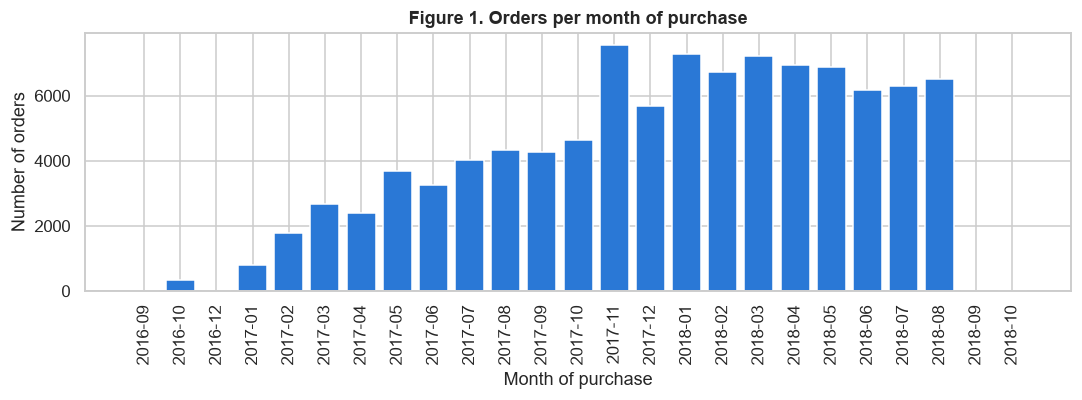

In [12]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])

status_counts = orders["order_status"].value_counts()
status_table = pd.DataFrame({"orders": status_counts,
                             "percent": 100 * status_counts / status_counts.sum()})
print(status_table)
print()
print("First purchase:", orders["order_purchase_timestamp"].min())
print("Last purchase: ", orders["order_purchase_timestamp"].max())

orders_per_month = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(orders_per_month.index.astype(str), orders_per_month.values, color=COLOURS[0])
ax.set_title("Figure 1. Orders per month of purchase")
ax.set_xlabel("Month of purchase")
ax.set_ylabel("Number of orders")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig01_orders_per_month.png"))
plt.show()

97% of the orders are delivered. There is no much activity between Sep and Dec. Order volume grows in 2017

# 2.4 Missing Values

In [13]:
date_columns = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
missing_by_status = orders.groupby("order_status")[date_columns].apply(lambda group: group.isna().sum())
missing_by_status["orders"] = orders["order_status"].value_counts()
print(missing_by_status)

print()
print("Missing values in products:")
print(products.isna().sum().to_string())

              order_approved_at  order_delivered_carrier_date  order_delivered_customer_date  orders
order_status                                                                                        
approved                      0                             2                              2       2
canceled                    141                           550                            619     625
created                       5                             5                              5       5
delivered                    14                             2                              8   96478
invoiced                      0                           314                            314     314
processing                    0                           301                            301     301
shipped                       0                             0                           1107    1107
unavailable                   0                           609                            60

Missing dates are structurally missing, they belong to orders that werent delivered meaning it is not random. 
Inn the product table, 610 lack a category and their description, 2 lack physical dimension category.

# 2.5 Date concistency checks
Orders should move forward in time, violations are recording errors

In [15]:
for column in ["order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[column] = pd.to_datetime(orders[column])

carrier_before_purchase = orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"]
carrier_before_approval = orders["order_delivered_carrier_date"] < orders["order_approved_at"]
delivered_before_carrier = orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]
cancelled_but_delivered = (orders["order_status"] == "canceled") & orders["order_delivered_customer_date"].notna()

print("Carrier hand over before purchase:      ", carrier_before_purchase.sum())
print("Carrier hand over before approval:      ", carrier_before_approval.sum())
print("Customer delivery before carrier pickup:", delivered_before_carrier.sum())
print("Cancelled orders with a delivery date:  ", cancelled_but_delivered.sum())

Carrier hand over before purchase:       166
Carrier hand over before approval:       1359
Customer delivery before carrier pickup: 23
Cancelled orders with a delivery date:   6


A small number of orders have unreal dates. they are too few to affect the model

# 2.6 Distribution and outliers

                         count    mean     std   min    1%    50%     99%       max
item price (BRL)   112,650.000 120.654 183.634 0.850 9.990 74.990 890.000 6,735.000
item freight (BRL) 112,650.000  19.990  15.806 0.000 4.420 16.260  84.520   409.680

                    count   mean   std   min    1%    50%    95%    99%     max
delivery_days  96,470.000 12.558 9.546 0.533 1.825 10.217 29.274 46.050 209.629
estimated_days 96,470.000 23.736 8.761 2.008 6.054 23.231 38.418 50.211 155.135

Items with zero freight: 383


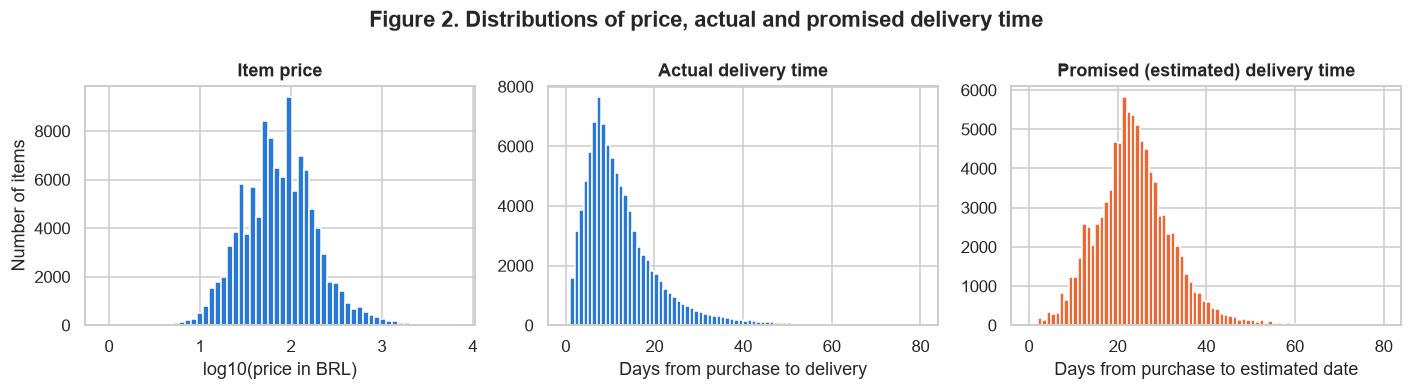

In [16]:
delivered_orders = orders[(orders["order_status"] == "delivered") &
                          orders["order_delivered_customer_date"].notna()].copy()
delivered_orders["delivery_days"] = ((delivered_orders["order_delivered_customer_date"] -
                                      delivered_orders["order_purchase_timestamp"]).dt.total_seconds() / 86400)
delivered_orders["estimated_days"] = ((delivered_orders["order_estimated_delivery_date"] -
                                       delivered_orders["order_purchase_timestamp"]).dt.total_seconds() / 86400)

summary_columns = pd.DataFrame({
    "item price (BRL)": items["price"],
    "item freight (BRL)": items["freight_value"],
})
print(summary_columns.describe(percentiles=[0.01, 0.5, 0.99]).T)
print()
print(delivered_orders[["delivery_days", "estimated_days"]].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T)
print()
print("Items with zero freight:", (items["freight_value"] == 0).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(np.log10(items["price"]), bins=60, color=COLOURS[0])
axes[0].set_title("Item price")
axes[0].set_xlabel("log10(price in BRL)")
axes[0].set_ylabel("Number of items")
axes[1].hist(delivered_orders["delivery_days"], bins=80, range=(0, 80), color=COLOURS[0])
axes[1].set_title("Actual delivery time")
axes[1].set_xlabel("Days from purchase to delivery")
axes[2].hist(delivered_orders["estimated_days"], bins=80, range=(0, 80), color=COLOURS[1])
axes[2].set_title("Promised (estimated) delivery time")
axes[2].set_xlabel("Days from purchase to estimated date")
fig.suptitle("Figure 2. Distributions of price, actual and promised delivery time", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig02_distributions.png"))
plt.show()

Prices and delivery time are skewed to the right. Median delivery takes about 10 days, but the 99th percentile is over 45 days

# 2.7 How often are several categories bought together

In [17]:
items_with_category = items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")

categories_per_order = items_with_category.groupby("order_id")["product_category_name"].nunique()
products_per_order = items_with_category.groupby("order_id")["product_id"].nunique()
items_per_order = items_with_category.groupby("order_id").size()

print("Orders with at least one item:            ", len(items_per_order))
print("Orders with 2+ items:                     ", (items_per_order >= 2).sum())
print("Orders with 2+ different products:        ", (products_per_order >= 2).sum())
print("Orders with 2+ different categories:      ", (categories_per_order >= 2).sum(),
      f"({100 * (categories_per_order >= 2).mean():.2f}% of orders)")

orders_with_customer = orders.merge(customers, on="customer_id")
orders_per_person = orders_with_customer.groupby("customer_unique_id")["order_id"].nunique()
print()
print("Unique customers (customer_unique_id):    ", len(orders_per_person))
print("Customers with 2+ orders:                 ", (orders_per_person >= 2).sum(),
      f"({100 * (orders_per_person >= 2).mean():.2f}%)")

Orders with at least one item:             98666
Orders with 2+ items:                      9803
Orders with 2+ different products:         3236
Orders with 2+ different categories:       727 (0.74% of orders)

Unique customers (customer_unique_id):     96096
Customers with 2+ orders:                  2997 (3.12%)


Fewer than 1% of orders contain more than one product category and 3.12% of customers have ordered twice

# 2.8 Data quality checks (Geolocation and payments)

In [18]:
inside_brazil = (geolocation["geolocation_lat"].between(-34, 5.5) &
                 geolocation["geolocation_lng"].between(-74, -34))
print("Geolocation rows:                ", len(geolocation))
print("Exact duplicate geolocation rows:", geolocation.duplicated().sum())
print("Rows outside Brazil's bounding box:", (~inside_brazil).sum())
print("Distinct zip-code prefixes:      ", geolocation["geolocation_zip_code_prefix"].nunique())

payment_total = payments.groupby("order_id")["payment_value"].sum()
item_total = items.groupby("order_id")["price"].sum() + items.groupby("order_id")["freight_value"].sum()
money_check = pd.DataFrame({"paid": payment_total, "items_plus_freight": item_total}).dropna()
money_check["gap"] = money_check["paid"] - money_check["items_plus_freight"]
print()
print("Orders where payment differs from items + freight by more than BRL 1:",
      (money_check["gap"].abs() > 1).sum())
print()
print(payments["payment_type"].value_counts().to_string())

Geolocation rows:                 1000163
Exact duplicate geolocation rows: 261831
Rows outside Brazil's bounding box: 42
Distinct zip-code prefixes:       19015

Orders where payment differs from items + freight by more than BRL 1: 249

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3


The geolocation table has many repeated coordinates per zip-code prefix and some points that fall outside Brazil.
A few hundred orders were paid an amount that differs from their items plus freight. could be discounts, vouchers or interest

## 3 Data Preparation

In [19]:
# i). convert text dates into proper datetime values
for column in ["review_creation_date", "review_answer_timestamp"]:
    reviews[column] = pd.to_datetime(reviews[column])
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

# ii) English category names. Two Portuguese names have no translation in the
# file, so they are added by hand. Products without any category become unknown.
extra_translations = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "kitchen_portables_and_food_preparers"],
})
translation_full = pd.concat([translation, extra_translations], ignore_index=True)

products_clean = products.merge(translation_full, on="product_category_name", how="left")
products_clean["category"] = products_clean["product_category_name_english"].fillna("unknown")
products_clean["volume_cm3"] = (products_clean["product_length_cm"] *
                                products_clean["product_height_cm"] *
                                products_clean["product_width_cm"])
print("Products without a category:", (products_clean["category"] == "unknown").sum())

# iii) one review per order - keep the review that was answered last
reviews_sorted = reviews.sort_values("review_answer_timestamp")
reviews_clean = reviews_sorted.drop_duplicates(subset="order_id", keep="last")
print("Reviews before:", len(reviews), " after keeping one per order:", len(reviews_clean))


Products without a category: 610
Reviews before: 99224  after keeping one per order: 98673


# iv) For geolocation, computation is on one coordinate per zip-code prefix and then the straight-line (haversine) distance between seller and customer. The haversine formula gives the great-circle distance between two points on a sphere. It understates road distance, but it ranks routes sensibly, which is what a model needs.

In [20]:
geo_valid = geolocation[inside_brazil]
zip_coordinates = geo_valid.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
print("Zip prefixes with a coordinate:", len(zip_coordinates))


def haversine_km(lat1, lng1, lat2, lng2):
    # Great-circle distance in kilometres between two sets of points (degrees in, km out)
    lat1, lng1, lat2, lng2 = np.radians(lat1), np.radians(lng1), np.radians(lat2), np.radians(lng2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

Zip prefixes with a coordinate: 19010


v)  one row per order whereby Items, products, sellers and payments are aggregated to order level. For orders with several items, the category, seller state and seller location are taken from the most expensive item, which is the item most likely to drive shipping. The number of different sellers is kept as its own feature, because multi-seller orders need several shipments.

In [21]:
item_details = items.merge(products_clean[["product_id", "category", "product_weight_g", "volume_cm3"]],
                           on="product_id", how="left")
item_details = item_details.merge(sellers, on="seller_id", how="left")
item_details = item_details.merge(zip_coordinates, left_on="seller_zip_code_prefix",
                                  right_index=True, how="left")
item_details = item_details.rename(columns={"geolocation_lat": "seller_lat", "geolocation_lng": "seller_lng"})

# sort so that the most expensive item of each order comes first
item_details = item_details.sort_values(["order_id", "price"], ascending=[True, False])
grouped_items = item_details.groupby("order_id")

order_features = pd.DataFrame({
    "n_items": grouped_items.size(),
    "n_sellers": grouped_items["seller_id"].nunique(),
    "n_categories": grouped_items["category"].nunique(),
    "total_price": grouped_items["price"].sum(),
    "total_freight": grouped_items["freight_value"].sum(),
    "total_weight_g": grouped_items["product_weight_g"].sum(min_count=1),
    "total_volume_cm3": grouped_items["volume_cm3"].sum(min_count=1),
    "main_category": grouped_items["category"].first(),
    "seller_state": grouped_items["seller_state"].first(),
    "seller_lat": grouped_items["seller_lat"].first(),
    "seller_lng": grouped_items["seller_lng"].first(),
})

grouped_payments = payments.groupby("order_id")
payment_features = pd.DataFrame({
    "payment_type": grouped_payments["payment_type"].first(),
    "installments": grouped_payments["payment_installments"].max(),
    "amount_paid": grouped_payments["payment_value"].sum(),
})
order_features = order_features.join(payment_features, how="left")

order_table = orders.merge(customers, on="customer_id", how="left")
order_table = order_table.merge(order_features, left_on="order_id", right_index=True, how="inner")
order_table = order_table.merge(zip_coordinates, left_on="customer_zip_code_prefix",
                                right_index=True, how="left")
order_table = order_table.rename(columns={"geolocation_lat": "customer_lat", "geolocation_lng": "customer_lng"})
order_table = order_table.merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left")

order_table["distance_km"] = haversine_km(order_table["seller_lat"], order_table["seller_lng"],
                                          order_table["customer_lat"], order_table["customer_lng"])
order_table["same_state"] = (order_table["customer_state"] == order_table["seller_state"]).astype(int)
order_table["freight_ratio"] = order_table["total_freight"] / order_table["total_price"]
order_table["payment_gap"] = order_table["amount_paid"] - (order_table["total_price"] + order_table["total_freight"])
order_table["purchase_dow"] = order_table["order_purchase_timestamp"].dt.dayofweek
order_table["purchase_hour"] = order_table["order_purchase_timestamp"].dt.hour
order_table["estimated_days"] = ((order_table["order_estimated_delivery_date"] -
                                  order_table["order_purchase_timestamp"]).dt.total_seconds() / 86400)

print("Order table:", order_table.shape)
print("Orders with no distance (missing zip coordinate):", order_table["distance_km"].isna().sum())

Order table: (98666, 36)
Orders with no distance (missing zip coordinate): 490


C:\Users\david.kalemba\AppData\Local\Temp\ipykernel_1244\295374786.py:46: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  order_table["purchase_dow"] = order_table["order_purchase_timestamp"].dt.dayofweek


# The delivery data set and the 2 target
delivery_day = time from purchase to delivery, in days
is_late = 1 if the calendar date of delivery falls after the estimated delivery date.

In [22]:
preparation_log = []
preparation_log.append({"step": "All orders", "rows": len(orders)})
preparation_log.append({"step": "Orders with at least one item (P5)", "rows": len(order_table)})

delivery_data = order_table[order_table["order_status"] == "delivered"].copy()
preparation_log.append({"step": "Status = delivered", "rows": len(delivery_data)})

delivery_data = delivery_data[delivery_data["order_delivered_customer_date"].notna()]
preparation_log.append({"step": "Has a customer delivery date", "rows": len(delivery_data)})

delivery_data = delivery_data[(delivery_data["order_purchase_timestamp"] >= "2017-01-01") &
                              (delivery_data["order_purchase_timestamp"] < "2018-09-01")]
preparation_log.append({"step": "Purchased Jan 2017 - Aug 2018 (P6)", "rows": len(delivery_data)})

delivery_data["delivery_days"] = ((delivery_data["order_delivered_customer_date"] -
                                   delivery_data["order_purchase_timestamp"]).dt.total_seconds() / 86400)
delivery_date_only = delivery_data["order_delivered_customer_date"].dt.normalize()
delivery_data["is_late"] = (delivery_date_only > delivery_data["order_estimated_delivery_date"]).astype(int)
delivery_data["days_late"] = ((delivery_data["order_delivered_customer_date"] -
                               delivery_data["order_estimated_delivery_date"]).dt.total_seconds() / 86400)
delivery_data = delivery_data.sort_values("order_purchase_timestamp").reset_index(drop=True)

preparation_log = pd.DataFrame(preparation_log)
preparation_log.to_csv(os.path.join(RESULTS_FOLDER, "preparation_log.csv"), index=False)
print(preparation_log.to_string(index=False))
print()
print(f"Late rate: {delivery_data['is_late'].mean():.4f}  ({delivery_data['is_late'].sum()} late orders)")
print(f"Mean delivery days: {delivery_data['delivery_days'].mean():.2f},  median: {delivery_data['delivery_days'].median():.2f}")

                              step  rows
                        All orders 99441
Orders with at least one item (P5) 98666
                Status = delivered 96478
      Has a customer delivery date 96470
Purchased Jan 2017 - Aug 2018 (P6) 96203

Late rate: 0.0679  (6531 late orders)
Mean delivery days: 12.54,  median: 10.21


6.79% of delivered orders arrive late, so the classification target is imbalanced. Accuracy would be misleading

# Is lateness stable over time?
If the late rate changes overtime, a random train/test split would let a model see the future. So we check for that before the evaluation design is fixed

                          orders  late_rate  mean_actual_days  mean_promised_days
order_purchase_timestamp                                                         
2017-01                      750      0.029            12.647              39.509
2017-02                     1653      0.030            13.169              31.849
2017-03                     2546      0.046            12.951              24.732
2017-04                     2303      0.066            14.918              27.350
2017-05                     3545      0.030            11.322              24.285
2017-06                     3135      0.030            12.012              24.022
2017-07                     3872      0.028            11.593              23.317
2017-08                     4193      0.029            11.147              23.481
2017-09                     4150      0.044            11.851              22.437
2017-10                     4478      0.042            11.857              23.020
2017-11         

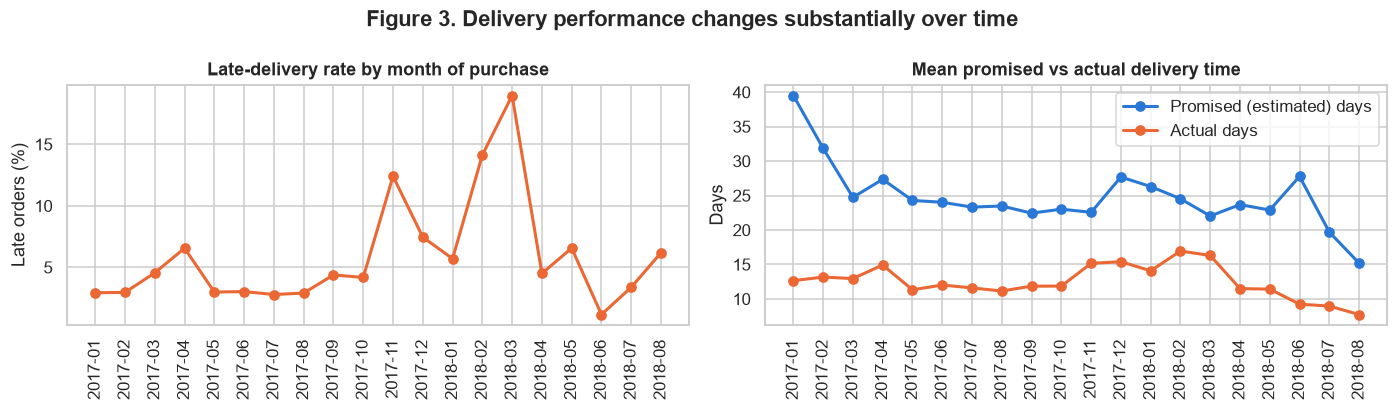

In [23]:
purchase_month = delivery_data["order_purchase_timestamp"].dt.to_period("M")
monthly_delivery = delivery_data.groupby(purchase_month).agg(
    orders=("order_id", "size"),
    late_rate=("is_late", "mean"),
    mean_actual_days=("delivery_days", "mean"),
    mean_promised_days=("estimated_days", "mean"),
)
monthly_delivery.to_csv(os.path.join(RESULTS_FOLDER, "monthly_delivery.csv"))
print(monthly_delivery)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
month_labels = monthly_delivery.index.astype(str)
axes[0].plot(month_labels, 100 * monthly_delivery["late_rate"], marker="o", color=COLOURS[1], linewidth=2)
axes[0].set_title("Late-delivery rate by month of purchase")
axes[0].set_ylabel("Late orders (%)")
axes[0].tick_params(axis="x", rotation=90)
axes[1].plot(month_labels, monthly_delivery["mean_promised_days"], marker="o", color=COLOURS[0],
             linewidth=2, label="Promised (estimated) days")
axes[1].plot(month_labels, monthly_delivery["mean_actual_days"], marker="o", color=COLOURS[1],
             linewidth=2, label="Actual days")
axes[1].set_title("Mean promised vs actual delivery time")
axes[1].set_ylabel("Days")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend()
fig.suptitle("Figure 3. Delivery performance changes substantially over time", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig03_monthly_delivery.png"))
plt.show()

Late rates range from under 3%  in some nothern sttates to iver 20% in AL. The chi-square test confirms that lateness is not independent of the customer's state.

# 4. Product categories frequentl purchased together
Association analysis finds items that occur together in transactions (Agrawal et al.). Because the numbers of co-occurrences are small, a high lift could arise by chance. Each pair is therefore tested with a one-sided Fisher's exact test, and the p-values are adjusted with the Benjamini–Hochberg false discovery rate (FDR) procedure because many pairs are tested at once.

In [24]:
valid_orders = orders[~orders["order_status"].isin(["canceled", "unavailable"])]
basket_items = items.merge(products_clean[["product_id", "category"]], on="product_id", how="left")
basket_items = basket_items.merge(valid_orders[["order_id", "customer_id"]], on="order_id", how="inner")
basket_items = basket_items.merge(customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
basket_items = basket_items[basket_items["category"] != "unknown"]


def make_basket_matrix(item_rows, basket_column):
    # One row per basket, one True/False column per category
    counts = item_rows.groupby([basket_column, "category"]).size().unstack(fill_value=0)
    return counts > 0


order_baskets_all = make_basket_matrix(basket_items, "order_id")
customer_baskets_all = make_basket_matrix(basket_items, "customer_unique_id")

order_baskets = order_baskets_all[order_baskets_all.sum(axis=1) >= 2]
customer_baskets = customer_baskets_all[customer_baskets_all.sum(axis=1) >= 2]

print("Order baskets (all):              ", len(order_baskets_all))
print("Order baskets with 2+ categories: ", len(order_baskets))
print("Customer baskets (all):           ", len(customer_baskets_all))
print("Customer baskets with 2+ categories:", len(customer_baskets))

Order baskets (all):               96824
Order baskets with 2+ categories:  726
Customer baskets (all):            93684
Customer baskets with 2+ categories: 2195


Lets defines a function that takes a basket matrix, runs Apriori, and returns one row per category pair with its support, confidence (in both directions), lift, Fisher p-value and FDR-adjusted q-value.

In [27]:
def pair_rules(baskets, min_count, all_baskets=None):
    n_baskets = len(baskets)
    frequent = apriori(baskets, min_support=min_count / n_baskets, use_colnames=True, max_len=3)
    frequent["size"] = frequent["itemsets"].apply(len)
    print(f"  frequent itemsets: {len(frequent)} "
          f"(pairs: {(frequent['size'] == 2).sum()}, triples: {(frequent['size'] == 3).sum()})")

    rows = []
    for itemset in frequent.loc[frequent["size"] == 2, "itemsets"]:
        cat_a, cat_b = sorted(itemset)
        has_a = baskets[cat_a]
        has_b = baskets[cat_b]
        both = int((has_a & has_b).sum())
        only_a = int((has_a & ~has_b).sum())
        only_b = int((~has_a & has_b).sum())
        neither = n_baskets - both - only_a - only_b

        # One-sided Fisher test: do A and B occur together MORE often than chance?
        odds_ratio, p_value = stats.fisher_exact([[both, only_a], [only_b, neither]], alternative="greater")

        row = {
            "category_A": cat_a, "category_B": cat_b, "baskets_with_both": both,
            "support": both / n_baskets,
            "confidence_A_to_B": both / has_a.sum(),
            "confidence_B_to_A": both / has_b.sum(),
            "lift": (both / n_baskets) / ((has_a.sum() / n_baskets) * (has_b.sum() / n_baskets)),
            "p_value": p_value,
        }
        if all_baskets is not None:
            n_all = len(all_baskets)
            row["lift_all_baskets"] = (both / n_all) / ((all_baskets[cat_a].sum() / n_all) *
                                                        (all_baskets[cat_b].sum() / n_all))
        rows.append(row)

    rules = pd.DataFrame(rows)
    # Benjamini-Hochberg correction because many pairs are tested
    rules["q_value"] = multipletests(rules["p_value"], method="fdr_bh")[1]
    rules["significant"] = rules["q_value"] < 0.05
    return rules.sort_values("lift", ascending=False).reset_index(drop=True)


print("Order level:")
order_rules = pair_rules(order_baskets, min_count=10, all_baskets=order_baskets_all)
print("Customer level:")
customer_rules = pair_rules(customer_baskets, min_count=15, all_baskets=customer_baskets_all)

order_rules.to_csv(os.path.join(RESULTS_FOLDER, "task2_order_rules.csv"), index=False)
customer_rules.to_csv(os.path.join(RESULTS_FOLDER, "task2_customer_rules.csv"), index=False)
order_rules

Order level:
  frequent itemsets: 43 (pairs: 17, triples: 0)
Customer level:
  frequent itemsets: 72 (pairs: 35, triples: 0)


,category_A,category_B,baskets_with_both,support,confidence_A_to_B,confidence_B_to_A,lift,p_value,lift_all_baskets,q_value,significant
0,health_beauty,perfumery,11,0.015,0.159,0.440,4.630,0.000,0.038,0.000,True
1,bed_bath_table,home_confort,43,0.059,0.217,0.860,3.153,0.000,1.116,0.000,True
2,baby,toys,19,0.026,0.204,0.380,2.966,0.000,0.166,0.000,True
3,baby,cool_stuff,20,0.028,0.215,0.303,2.366,0.000,0.187,0.000,True
4,health_beauty,sports_leisure,14,0.019,0.203,0.209,2.199,0.002,0.020,0.008,True
5,construction_tools_lights,furniture_decor,11,0.015,0.611,0.054,2.186,0.003,0.682,0.008,True
6,furniture_decor,home_construction,13,0.018,0.064,0.500,1.788,0.013,0.401,0.027,True
7,bed_bath_table,furniture_decor,70,0.096,0.354,0.345,1.264,0.005,0.112,0.012,True
8,housewares,sports_leisure,11,0.015,0.108,0.164,1.169,0.333,0.024,0.629,False
9,garden_tools,housewares,11,0.015,0.151,0.108,1.073,0.452,0.052,0.768,False


No category triple reaches the minimum count, so multi-category purchases are almost always pairs.

In [28]:
customer_rules

,category_A,category_B,baskets_with_both,support,confidence_A_to_B,confidence_B_to_A,lift,p_value,lift_all_baskets,q_value,significant
0,bed_bath_table,home_confort,54,0.025,0.101,0.740,3.024,0.000,1.400,0.000,True
1,construction_tools_lights,furniture_decor,18,0.008,0.600,0.035,2.572,0.000,1.103,0.000,True
2,baby,cool_stuff,31,0.014,0.182,0.196,2.533,0.000,0.284,0.000,True
3,baby,toys,27,0.012,0.159,0.157,2.027,0.000,0.233,0.002,True
4,computers_accessories,telephony,20,0.009,0.099,0.161,1.753,0.008,0.069,0.039,True
5,health_beauty,perfumery,25,0.011,0.093,0.200,1.638,0.007,0.087,0.039,True
6,furniture_decor,home_construction,20,0.009,0.039,0.357,1.531,0.023,0.610,0.101,False
7,health_beauty,stationery,15,0.007,0.056,0.155,1.267,0.197,0.071,0.764,False
8,bed_bath_table,furniture_decor,155,0.071,0.289,0.303,1.237,0.000,0.253,0.003,True
9,health_beauty,sports_leisure,39,0.018,0.146,0.137,1.121,0.234,0.057,0.818,False


## 4.2 Do the two basket definitions agree

In [29]:
order_rules["pair"] = order_rules["category_A"] + " + " + order_rules["category_B"]
customer_rules["pair"] = customer_rules["category_A"] + " + " + customer_rules["category_B"]

comparison = order_rules[["pair", "baskets_with_both", "lift", "q_value"]].merge(
    customer_rules[["pair", "baskets_with_both", "lift", "q_value"]],
    on="pair", how="outer", suffixes=("_order", "_customer"))
comparison = comparison.sort_values("lift_order", ascending=False)

significant_both = comparison[(comparison["q_value_order"] < 0.05) & (comparison["q_value_customer"] < 0.05)]
print("Pairs significant at BOTH levels:")
print(significant_both.to_string(index=False))
comparison.to_csv(os.path.join(RESULTS_FOLDER, "level_comparison.csv"), index=False)

Pairs significant at BOTH levels:
                                       pair  baskets_with_both_order  lift_order  q_value_order  baskets_with_both_customer  lift_customer  q_value_customer
                  health_beauty + perfumery                   11.000       4.630          0.000                          25          1.638             0.039
              bed_bath_table + home_confort                   43.000       3.153          0.000                          54          3.024             0.000
                                baby + toys                   19.000       2.966          0.000                          27          2.027             0.002
                          baby + cool_stuff                   20.000       2.366          0.000                          31          2.533             0.000
construction_tools_lights + furniture_decor                   11.000       2.186          0.008                          18          2.572             0.000
           bed_bath_tabl

## 4.3 Bootsrap confidence intervals for lift
With only a few hundred multi-category orders, the lift estimates are uncertain.

                                       pair  lift  lower_95  upper_95
                  health_beauty + perfumery 4.630     2.618     6.723
              bed_bath_table + home_confort 3.153     2.714     3.615
                                baby + toys 2.966     2.053     4.094
                          baby + cool_stuff 2.366     1.577     3.193
             health_beauty + sports_leisure 2.199     1.264     3.124
construction_tools_lights + furniture_decor 2.186     1.337     3.050
        furniture_decor + home_construction 1.788     1.149     2.508
           bed_bath_table + furniture_decor 1.264     1.053     1.477


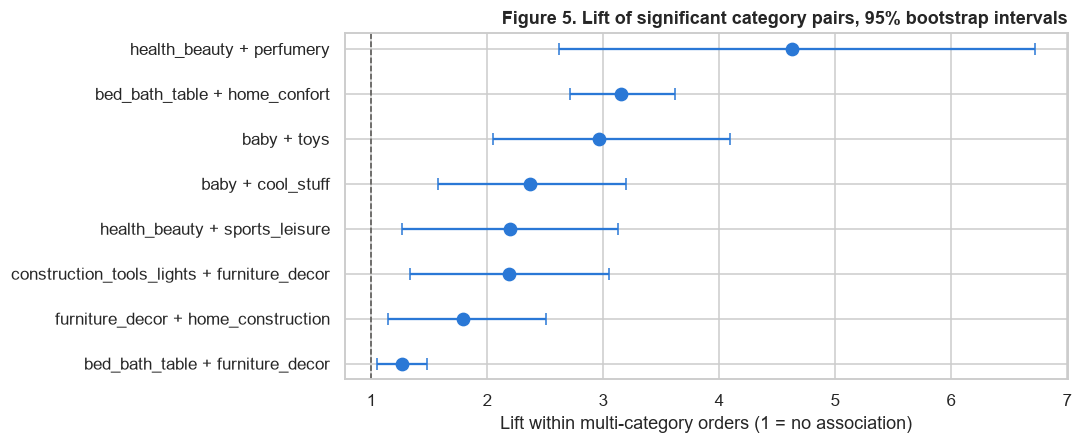

In [30]:
significant_pairs = order_rules[order_rules["significant"]][["category_A", "category_B"]].values.tolist()
rng = np.random.default_rng(RANDOM_SEED)
basket_array = order_baskets.values
column_position = {name: i for i, name in enumerate(order_baskets.columns)}
n_baskets = basket_array.shape[0]

bootstrap_lifts = {f"{a} + {b}": [] for a, b in significant_pairs}
for repeat in range(1000):
    sample_rows = rng.integers(0, n_baskets, size=n_baskets)
    sample = basket_array[sample_rows]
    for cat_a, cat_b in significant_pairs:
        has_a = sample[:, column_position[cat_a]]
        has_b = sample[:, column_position[cat_b]]
        p_a, p_b, p_ab = has_a.mean(), has_b.mean(), (has_a & has_b).mean()
        if p_a > 0 and p_b > 0:
            bootstrap_lifts[f"{cat_a} + {cat_b}"].append(p_ab / (p_a * p_b))

interval_rows = []
for pair_name, values in bootstrap_lifts.items():
    interval_rows.append({"pair": pair_name,
                          "lift": order_rules.loc[order_rules["pair"] == pair_name, "lift"].values[0],
                          "lower_95": np.percentile(values, 2.5),
                          "upper_95": np.percentile(values, 97.5)})
lift_intervals = pd.DataFrame(interval_rows).sort_values("lift", ascending=False)
lift_intervals.to_csv(os.path.join(RESULTS_FOLDER, "task2_bootstrap.csv"), index=False)
print(lift_intervals.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.2))
y_positions = np.arange(len(lift_intervals))
ax.errorbar(lift_intervals["lift"], y_positions,
            xerr=[lift_intervals["lift"] - lift_intervals["lower_95"],
                  lift_intervals["upper_95"] - lift_intervals["lift"]],
            fmt="o", color=COLOURS[0], ecolor=COLOURS[0], capsize=4, markersize=8)
ax.axvline(1, color="#52514e", linestyle="--", linewidth=1)
ax.set_yticks(y_positions)
ax.set_yticklabels(lift_intervals["pair"])
ax.invert_yaxis()
ax.set_xlabel("Lift within multi-category orders (1 = no association)")
ax.set_title("Figure 5. Lift of significant category pairs, 95% bootstrap intervals", loc="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig05_lift_intervals.png"))
plt.show()

## Sensitivity to the minimum count threshold
The minimum count is a judgement call, so we repeat the order-level analysis with thresholds of 5, 10 and 20 baskets and check whether the significant pairs change.

In [31]:
sensitivity_rows = []
for threshold in [5, 10, 20]:
    print(f"Threshold = {threshold}")
    rules = pair_rules(order_baskets, min_count=threshold)
    significant = rules[rules["significant"]]
    sensitivity_rows.append({
        "min_count": threshold,
        "pairs_tested": len(rules),
        "significant_pairs": len(significant),
        "significant_list": "; ".join(significant["category_A"] + "+" + significant["category_B"]),
    })
threshold_sensitivity = pd.DataFrame(sensitivity_rows)
threshold_sensitivity.to_csv(os.path.join(RESULTS_FOLDER, "task2_threshold_sensitivity.csv"), index=False)
threshold_sensitivity

Threshold = 5
  frequent itemsets: 73 (pairs: 36, triples: 0)
Threshold = 10
  frequent itemsets: 43 (pairs: 17, triples: 0)
Threshold = 20
  frequent itemsets: 23 (pairs: 5, triples: 0)


,min_count,pairs_tested,significant_pairs,significant_list
0,5,36,16,audio+watches_gifts; luggage_accessories+stati...
1,10,17,8,health_beauty+perfumery; bed_bath_table+home_c...
2,20,5,3,bed_bath_table+home_confort; baby+cool_stuff; ...


The threshold changes how many pairs are found, but not which pairs matter. At a minimum of 5 baskets, 36 pairs are tested and 16 are significant.

# Segmenting sellers by sales and service characteristics
For each seller we compute features in two groups,1. Sales: total revenue, average item price, number of categories sold. 2. Service: late-delivery rate, median handling time (approval → hand-over to carrier), mean review score, cancellation rate.

In [32]:
seller_rows = items.merge(orders, on="order_id", how="inner")
seller_rows = seller_rows.merge(products_clean[["product_id", "category"]], on="product_id", how="left")
seller_rows = seller_rows.merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left")

delivered_date = seller_rows["order_delivered_customer_date"].dt.normalize()
seller_rows["late"] = np.where(seller_rows["order_delivered_customer_date"].notna(),
                               (delivered_date > seller_rows["order_estimated_delivery_date"]).astype(float),
                               np.nan)
seller_rows["handling_days"] = ((seller_rows["order_delivered_carrier_date"] -
                                 seller_rows["order_approved_at"]).dt.total_seconds() / 86400)
seller_rows.loc[seller_rows["handling_days"] < 0, "handling_days"] = np.nan
seller_rows["missed_shipping_limit"] = np.where(
    seller_rows["order_delivered_carrier_date"].notna(),
    (seller_rows["order_delivered_carrier_date"] > seller_rows["shipping_limit_date"]).astype(float), np.nan)
seller_rows["cancelled"] = seller_rows["order_status"].isin(["canceled", "unavailable"]).astype(int)

# Collapsing to one row per (seller, order) so that multi-item orders are not counted twice
seller_orders = seller_rows.groupby(["seller_id", "order_id"]).agg(
    revenue=("price", "sum"), freight=("freight_value", "sum"), n_items=("price", "size"),
    late=("late", "first"), handling_days=("handling_days", "first"),
    missed_shipping_limit=("missed_shipping_limit", "max"), review_score=("review_score", "first"),
    cancelled=("cancelled", "first"), purchase_time=("order_purchase_timestamp", "first"),
).reset_index()

seller_category_counts = seller_rows.groupby("seller_id")["category"].nunique()

grouped_sellers = seller_orders.groupby("seller_id")
seller_profile = pd.DataFrame({
    "n_orders": grouped_sellers.size(),
    "revenue": grouped_sellers["revenue"].sum(),
    "avg_price": grouped_sellers["revenue"].sum() / grouped_sellers["n_items"].sum(),
    "freight_ratio": grouped_sellers["freight"].sum() / grouped_sellers["revenue"].sum(),
    "n_categories": seller_category_counts,
    "late_rate": grouped_sellers["late"].mean(),
    "handling_days": grouped_sellers["handling_days"].median(),
    "missed_limit_rate": grouped_sellers["missed_shipping_limit"].mean(),
    "avg_review": grouped_sellers["review_score"].mean(),
    "cancel_rate": grouped_sellers["cancelled"].mean(),
    "months_active": (grouped_sellers["purchase_time"].max() -
                      grouped_sellers["purchase_time"].min()).dt.days / 30.44,
})
print("Sellers:", len(seller_profile))
print(seller_profile["n_orders"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).to_string())

Sellers: 3095
count   3,095.000
mean       32.313
std       105.140
min         1.000
25%         2.000
50%         6.000
75%        21.500
90%        69.600
max     1,854.000


correlations that justified leaving out the three duplicate features (after log-transforming the skewed ones), using sellers with at least 10 orders.

In [33]:
redundancy_check = seller_profile[seller_profile["n_orders"] >= 10].copy()
for feature in ["revenue", "n_orders", "avg_price", "handling_days"]:
    redundancy_check[feature] = np.log1p(redundancy_check[feature])
pairs_to_check = [("revenue", "n_orders"), ("handling_days", "missed_limit_rate"), ("avg_price", "freight_ratio")]
for feature_a, feature_b in pairs_to_check:
    r = redundancy_check[feature_a].corr(redundancy_check[feature_b])
    print(f"Correlation {feature_a} vs {feature_b}: r = {r:.2f}")

Correlation revenue vs n_orders: r = 0.78
Correlation handling_days vs missed_limit_rate: r = 0.75
Correlation avg_price vs freight_ratio: r = -0.80


## 5.2 Sellers that can be clustered reliably
Half of the sellers have six orders or fewer. A late rate computed from 3 orders can only be 0%, 33%, 67% or 100%, which is mostly noise. Clustering these sellers would group them by chance rather than by real behaviour. We therefore:

cluster the established sellers (≥ 10 orders), and
describe the remaining emerging sellers (< 10 orders) as a separate segment, using simple statistics.
A sensitivity check with a threshold of 20 orders is included.

In [35]:
MIN_ORDERS = 10
established = seller_profile[seller_profile["n_orders"] >= MIN_ORDERS].copy()
emerging = seller_profile[seller_profile["n_orders"] < MIN_ORDERS].copy()

print(f"Established sellers (>= {MIN_ORDERS} orders): {len(established)} "
      f"({100 * len(established) / len(seller_profile):.1f}% of sellers, "
      f"{100 * established['revenue'].sum() / seller_profile['revenue'].sum():.1f}% of revenue)")
print(f"Emerging sellers (< {MIN_ORDERS} orders):    {len(emerging)} "
      f"({100 * len(emerging) / len(seller_profile):.1f}% of sellers, "
      f"{100 * emerging['revenue'].sum() / seller_profile['revenue'].sum():.1f}% of revenue)")

cluster_features = ["revenue", "avg_price", "n_categories", "late_rate", "handling_days", "avg_review", "cancel_rate"]
skewed_features = ["revenue", "avg_price", "n_categories", "handling_days"]


def prepare_cluster_matrix(profile_table):
    # 1) log-transform skewed features, 2) fill the few gaps with the median, 3) standardise
    X = profile_table[cluster_features].copy()
    for feature in skewed_features:
        X[feature] = np.log1p(X[feature])
    X = X.fillna(X.median())
    return StandardScaler().fit_transform(X)


X_sellers = prepare_cluster_matrix(established)
print()
print("Correlation between the clustering features (after log transform):")
check = established[cluster_features].copy()
for feature in skewed_features:
    check[feature] = np.log1p(check[feature])
print(check.corr().round(2))

Established sellers (>= 10 orders): 1271 (41.1% of sellers, 90.6% of revenue)
Emerging sellers (< 10 orders):    1824 (58.9% of sellers, 9.4% of revenue)

Correlation between the clustering features (after log transform):
               revenue  avg_price  n_categories  late_rate  handling_days  avg_review  cancel_rate
revenue          1.000      0.540         0.260      0.050          0.030      -0.050       -0.050
avg_price        0.540      1.000        -0.060      0.080          0.070      -0.040        0.030
n_categories     0.260     -0.060         1.000     -0.090         -0.010      -0.040        0.050
late_rate        0.050      0.080        -0.090      1.000          0.320      -0.520        0.070
handling_days    0.030      0.070        -0.010      0.320          1.000      -0.430        0.150
avg_review      -0.050     -0.040        -0.040     -0.520         -0.430       1.000       -0.270
cancel_rate     -0.050      0.030         0.050      0.070          0.150      -0.270

k-means groups points by Euclidean distance, so (i) features on large scales (revenue in thousands of BRL) would dominate features on small scales (rates between 0 and 1), which is why every feature is standardised to mean 0 and standard deviation 1; and (ii) heavily skewed features would let a handful of very large sellers dominate the solution, which is why revenue, price, category count and handling time are log-transformed first (Han et al.).

## 5.3 Number of clusters to be used
combination of  the elbow in within-cluster sum of squares, he silhouette coefficient, agreement with a different algorithm and whether the segments are interpretable and actionable.

 k   inertia  silhouette  ARI_vs_ward                          cluster_sizes
 2 7,454.304       0.195        0.448                             [494, 777]
 3 6,378.925       0.172        0.451                        [600, 489, 182]
 4 5,692.094       0.181        0.470                    [223, 469, 553, 26]
 5 5,101.236       0.174        0.332               [436, 200, 340, 270, 25]
 6 4,735.227       0.174        0.349           [406, 59, 293, 250, 23, 240]
 7 4,460.683       0.146        0.394      [297, 193, 230, 71, 215, 22, 243]
 8 4,219.600       0.152        0.361 [175, 222, 171, 264, 155, 206, 56, 22]


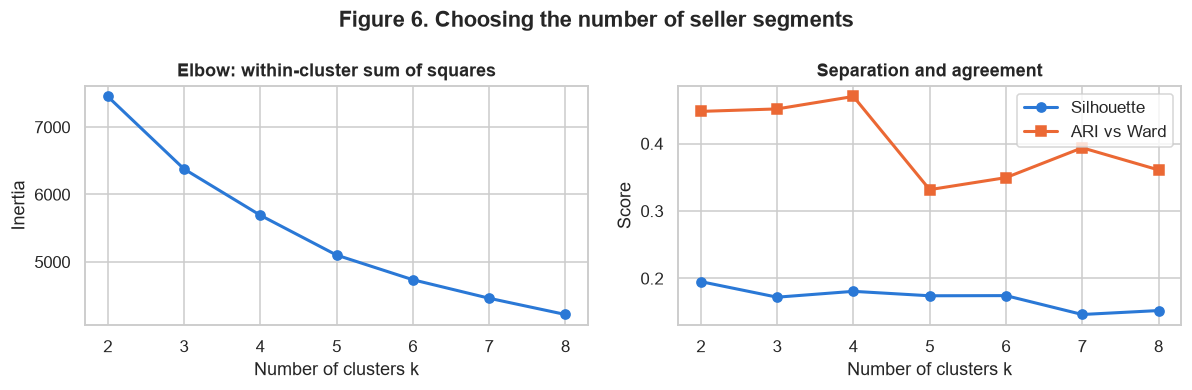

In [36]:
k_rows = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_SEED).fit(X_sellers)
    ward_labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_sellers)
    k_rows.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette": silhouette_score(X_sellers, kmeans.labels_),
        "ARI_vs_ward": adjusted_rand_score(kmeans.labels_, ward_labels),
        "cluster_sizes": str(np.bincount(kmeans.labels_).tolist()),
    })
k_selection = pd.DataFrame(k_rows)
k_selection.to_csv(os.path.join(RESULTS_FOLDER, "task3_k_selection.csv"), index=False)
print(k_selection.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_selection["k"], k_selection["inertia"], marker="o", color=COLOURS[0], linewidth=2)
axes[0].set_title("Elbow: within-cluster sum of squares")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_selection["k"], k_selection["silhouette"], marker="o", color=COLOURS[0], linewidth=2, label="Silhouette")
axes[1].plot(k_selection["k"], k_selection["ARI_vs_ward"], marker="s", color=COLOURS[1], linewidth=2, label="ARI vs Ward")
axes[1].set_title("Separation and agreement")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Score")
axes[1].legend()
fig.suptitle("Figure 6. Choosing the number of seller segments", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig06_k_selection.png"))
plt.show()

Silhouette values stay low for every k (well below 0.25), so sellers do not form sharply separated natural groups.
There is no sharp elbow. k = 2 has the highest silhouette
k = 4 has the highest agreement with Ward clustering

## 5.4 Stability of the k = 4 solution
Following Hennig, a cluster solution is only worth interpreting if it is reproduced when the data are perturbed. We check (a) different random starts and (b) 50 bootstrap resamples of the sellers.

In [37]:
K = 4
final_kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_SEED).fit(X_sellers)
final_labels = final_kmeans.labels_

seed_aris = []
for seed in range(1, 11):
    other = KMeans(n_clusters=K, n_init=20, random_state=seed).fit_predict(X_sellers)
    seed_aris.append(adjusted_rand_score(final_labels, other))

rng = np.random.default_rng(RANDOM_SEED)
bootstrap_aris = []
for repeat in range(50):
    sample_rows = rng.integers(0, len(X_sellers), size=len(X_sellers))
    boot_model = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_SEED).fit(X_sellers[sample_rows])
    bootstrap_aris.append(adjusted_rand_score(final_labels, boot_model.predict(X_sellers)))

print(f"ARI across 10 random starts: min {min(seed_aris):.3f}, mean {np.mean(seed_aris):.3f}")
print(f"ARI across 50 bootstrap samples: mean {np.mean(bootstrap_aris):.3f}, "
      f"5th percentile {np.percentile(bootstrap_aris, 5):.3f}")

stability_summary = pd.DataFrame({"check": ["random starts (min)", "random starts (mean)",
                                            "bootstrap (mean)", "bootstrap (5th pct)"],
                                  "ARI": [min(seed_aris), np.mean(seed_aris),
                                          np.mean(bootstrap_aris), np.percentile(bootstrap_aris, 5)]})
stability_summary.to_csv(os.path.join(RESULTS_FOLDER, "task3_stability.csv"), index=False)

ARI across 10 random starts: min 0.982, mean 0.995
ARI across 50 bootstrap samples: mean 0.718, 5th percentile 0.415


The solution is almost identical across random starts, so it is not an artefact of initialisation. Under bootstrap resampling the agreement is moderate on average but sometimes much lower. The largest segments are reproduced reliably, while the boundaries between neighbouring segments shift.

## 5.5 Profiling and naming the segments
Segments are named from their profiles by fixed rules, not by hand, so the names stay correct even if a different library version numbers the clusters differently:

i) the cluster with the highest mean cancellation rate - Cancellation-prone,
ii) of the rest, the one with the highest median late rate - Service-at-risk,
 iii) of the rest, the one with the highest median revenue - Established core,
the remaining cluster → Small reliable.

In [38]:
established["cluster"] = final_labels
cluster_mean_cancel = established.groupby("cluster")["cancel_rate"].mean()
cluster_median = established.groupby("cluster")[["late_rate", "revenue"]].median()

segment_names = {}
cancel_cluster = cluster_mean_cancel.idxmax()
segment_names[cancel_cluster] = "Cancellation-prone"
remaining = cluster_median.drop(index=cancel_cluster)
risk_cluster = remaining["late_rate"].idxmax()
segment_names[risk_cluster] = "Service-at-risk"
remaining = remaining.drop(index=risk_cluster)
core_cluster = remaining["revenue"].idxmax()
segment_names[core_cluster] = "Established core"
remaining = remaining.drop(index=core_cluster)
segment_names[remaining.index[0]] = "Small reliable"

established["segment"] = established["cluster"].map(segment_names)
emerging["segment"] = "Emerging (<10 orders)"
all_sellers_segmented = pd.concat([established, emerging])

profile_columns = ["n_orders", "revenue", "avg_price", "freight_ratio", "n_categories", "late_rate",
                   "handling_days", "missed_limit_rate", "avg_review", "cancel_rate", "months_active"]
segment_profile = all_sellers_segmented.groupby("segment")[profile_columns].median()
segment_profile.insert(0, "sellers", all_sellers_segmented.groupby("segment").size())
segment_profile.insert(1, "revenue_share_%", 100 * all_sellers_segmented.groupby("segment")["revenue"].sum()
                       / all_sellers_segmented["revenue"].sum())
segment_profile["mean_cancel_rate"] = all_sellers_segmented.groupby("segment")["cancel_rate"].mean()
segment_order = ["Established core", "Small reliable", "Service-at-risk", "Cancellation-prone", "Emerging (<10 orders)"]
segment_profile = segment_profile.loc[segment_order]
segment_profile.to_csv(os.path.join(RESULTS_FOLDER, "task3_segment_profile.csv"))
segment_profile.T

segment,Established core,Small reliable,Service-at-risk,Cancellation-prone,Emerging (<10 orders)
sellers,469.000,553.000,223.000,26.000,"1,824.000"
revenue_share_%,68.929,10.150,10.898,0.616,9.407
n_orders,63.000,20.000,24.000,12.500,2.000
revenue,"10,454.200","1,872.790","3,537.200","1,604.420",281.400
avg_price,146.243,70.169,98.520,92.376,92.107
freight_ratio,0.148,0.259,0.217,0.224,0.204
n_categories,4.000,2.000,2.000,2.000,1.000
late_rate,0.051,0.033,0.133,0.091,0.000
handling_days,1.629,1.256,3.934,2.888,1.955
missed_limit_rate,0.049,0.023,0.247,0.146,0.000


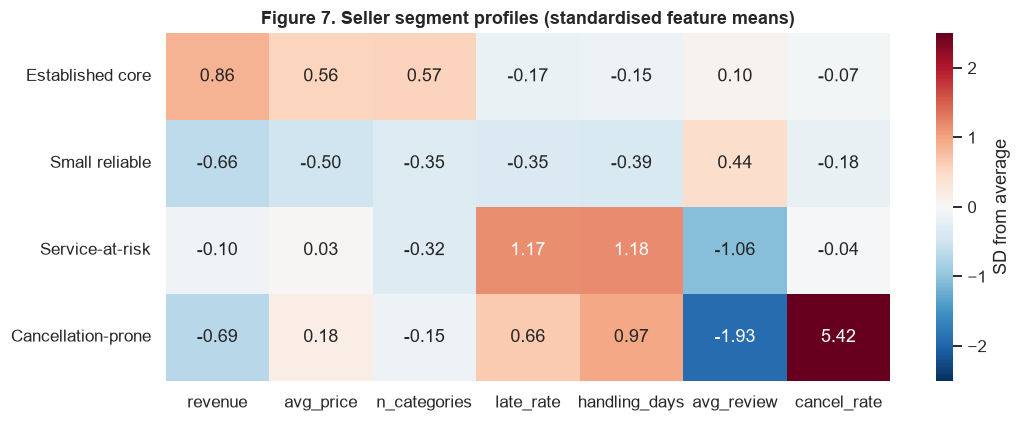

In [39]:
X_frame = pd.DataFrame(X_sellers, columns=cluster_features, index=established.index)
X_frame["segment"] = established["segment"]
centre_table = X_frame.groupby("segment")[cluster_features].mean().loc[segment_order[:4]]

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(centre_table, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5,
            cbar_kws={"label": "SD from average"}, ax=ax)
ax.set_title("Figure 7. Seller segment profiles (standardised feature means)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig07_segment_heatmap.png"))
plt.show()

The heat map shows each segment's standardised mean on the clustering features. Values are in standard deviations from the average established seller (0 = average), which makes the differences easier to read than the raw units.

## 5.6 Comparison with a simple rule-based baseline
Is k-means adding anything beyond a simple managerial rule

In [ ]:
high_sales = established["revenue"] > established["revenue"].median()
good_service = established["late_rate"].fillna(established["late_rate"].median()) <= established["late_rate"].median()
established["rule_segment"] = np.where(high_sales, "High sales", "Low sales")
established["rule_segment"] = established["rule_segment"] + " / " + np.where(good_service, "good service", "weaker service")

print(f"ARI between k-means segments and the 2x2 rule: "
      f"{adjusted_rand_score(established['segment'], established['rule_segment']):.3f}")
print()
print(pd.crosstab(established["segment"], established["rule_segment"]))

Agreement with the simple rule is low, so k-means is not just reproducing the 2 × 2 grid. It combines information the rule ignores i.e. handling time, reviews, price level and, above all, cancellations, which isolate a small but distinct group.

## 5.7 Sensitivity: threshold of 20 orders instead of 10

In [40]:
established_20 = seller_profile[seller_profile["n_orders"] >= 20].copy()
X_sellers_20 = prepare_cluster_matrix(established_20)
labels_20 = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_SEED).fit_predict(X_sellers_20)
print(f"Sellers with >= 20 orders: {len(established_20)}; silhouette (k=4): {silhouette_score(X_sellers_20, labels_20):.3f}")

common = established_20.index
labels_10_common = established.loc[common, "cluster"]
print(f"ARI between the >=10 and >=20 solutions on the shared sellers: "
      f"{adjusted_rand_score(labels_10_common, labels_20):.3f}")
established_20["cluster20"] = labels_20
print(established_20.groupby("cluster20")[["revenue", "avg_price", "late_rate", "handling_days",
                                           "avg_review", "cancel_rate"]].median())

Sellers with >= 20 orders: 818; silhouette (k=4): 0.151
ARI between the >=10 and >=20 solutions on the shared sellers: 0.514
             revenue  avg_price  late_rate  handling_days  avg_review  cancel_rate
cluster20                                                                         
0         13,492.875    179.134      0.049          1.459       4.232        0.000
1          9,606.115     89.494      0.053          1.613       4.098        0.000
2          3,069.780     60.451      0.041          1.242       4.281        0.000
3          5,324.150     98.520      0.123          3.609       3.769        0.000


Agreement between the two solutions on the sellers they share is moderate. With the stricter threshold, no cancellation-prone group appears, because sellers with many cancellations tend to have few orders, and the high-revenue sellers split into a higher-price and a lower-price group instead.

# 6 Identifying unusual orders for operational review

## 6.1 Approach
There are no labels saying which orders were problematic, so this is an unsupervised anomaly detection problem (Chandola et al.).
Without labels, we cannot measure accuracy directly. Instead we use review score as an external check: it is not used to build the anomaly score, so if flagged orders have clearly worse reviews and more late deliveries, the flags capture something that matters operationally.

## 6.2 Layer 1: rule-based flags (all orders)

In [ ]:
data_end = orders["order_purchase_timestamp"].max()
not_finished = ["shipped", "invoiced", "processing", "approved", "created"]

rule_flags = pd.DataFrame({"order_id": orders["order_id"]})
rule_flags["R1_delivered_without_date"] = ((orders["order_status"] == "delivered") &
                                           orders["order_delivered_customer_date"].isna())
rule_flags["R2_cancelled_but_delivered"] = cancelled_but_delivered
rule_flags["R3_impossible_date_order"] = carrier_before_purchase | delivered_before_carrier
rule_flags["R4_payment_mismatch"] = orders["order_id"].isin(money_check.index[money_check["gap"].abs() > 1])
rule_flags["R5_stuck_over_60_days"] = (orders["order_status"].isin(not_finished) &
                                       ((data_end - orders["order_purchase_timestamp"]).dt.days > 60))
days_late_all = (orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]).dt.days
rule_flags["R6_over_30_days_late"] = days_late_all > 30

rule_columns = [column for column in rule_flags.columns if column.startswith("R")]
rule_flags["any_rule"] = rule_flags[rule_columns].any(axis=1)
rule_summary = rule_flags[rule_columns + ["any_rule"]].sum().rename("orders_flagged")
rule_summary.to_csv(os.path.join(RESULTS_FOLDER, "task4_rule_summary.csv"))
print(rule_summary.to_string())

each rule targets a different operational process

## 6.3 Layers 2 and 3: statistical anomaly scores (delivered orders)
The statistical methods use delivered orders, because only those have the full set of delivery features. The features describe the order's value, logistics and payment

In [41]:
anomaly_features = ["total_price", "total_freight", "freight_ratio", "n_items", "n_sellers", "installments",
                    "total_weight_g", "distance_km", "delivery_days", "days_late", "payment_gap"]
log_features = ["total_price", "total_freight", "total_weight_g", "distance_km", "delivery_days"]

anomaly_data = delivery_data.copy()
X_anomaly = anomaly_data[anomaly_features].copy()
for feature in log_features:
    X_anomaly[feature] = np.log1p(X_anomaly[feature])
X_anomaly = X_anomaly.fillna(X_anomaly.median())

# Layer 2: robust z-score = 0.6745 * (x - median) / MAD
medians = X_anomaly.median()
mads = (X_anomaly - medians).abs().median()
print("Features whose MAD is zero (more than half the orders share one value):")
print(mads[mads == 0].index.tolist())

robust_z = pd.DataFrame(index=X_anomaly.index)
for feature in anomaly_features:
    if mads[feature] > 0:
        robust_z[feature] = 0.6745 * (X_anomaly[feature] - medians[feature]) / mads[feature]
    else:
        # fall back to the mean absolute deviation when the MAD is zero
        mean_abs_dev = (X_anomaly[feature] - X_anomaly[feature].mean()).abs().mean()
        robust_z[feature] = (X_anomaly[feature] - X_anomaly[feature].mean()) / (1.2533 * mean_abs_dev)

anomaly_data["robust_z_max"] = robust_z.abs().max(axis=1)
print()
print(f"Share of orders with |robust z| > 3.5 on at least one feature: "
      f"{100 * (anomaly_data['robust_z_max'] > 3.5).mean():.1f}%")

Features whose MAD is zero (more than half the orders share one value):
['n_items', 'n_sellers', 'payment_gap']

Share of orders with |robust z| > 3.5 on at least one feature: 25.7%


The usual cut-off of 3.5 flags far too many orders to be practical for a review team, because several features (number of items, number of sellers, payment gap) take the same value for most orders.

Isolation Forest needs no distributional assumption and no labels. Its results depend on the random seed, so we check stability across five seeds and then average the five scores, which is a simple way to make the ranking more stable.

In [42]:
X_anomaly_scaled = StandardScaler().fit_transform(X_anomaly)
REVIEW_SHARE = 0.01
n_review = int(REVIEW_SHARE * len(anomaly_data))

seed_scores = []
for seed in range(5):
    forest = IsolationForest(n_estimators=300, random_state=RANDOM_SEED + seed)
    forest.fit(X_anomaly_scaled)
    seed_scores.append(-forest.score_samples(X_anomaly_scaled))   # higher = more unusual


def top_set(scores, n):
    return set(np.argsort(-np.asarray(scores))[:n])


def jaccard(set_a, set_b):
    return len(set_a & set_b) / len(set_a | set_b)


first_top = top_set(seed_scores[0], n_review)
seed_overlaps = [jaccard(first_top, top_set(scores, n_review)) for scores in seed_scores[1:]]
print("Jaccard overlap of the top-1% queue between seed 1 and seeds 2-5:", np.round(seed_overlaps, 3))

anomaly_data["iforest_score"] = np.mean(seed_scores, axis=0)
iforest_top = top_set(anomaly_data["iforest_score"], n_review)
robust_top = top_set(anomaly_data["robust_z_max"], n_review)
print("Jaccard overlap between Isolation Forest and robust-z top-1% queues:",
      round(jaccard(iforest_top, robust_top), 3))

Jaccard overlap of the top-1% queue between seed 1 and seeds 2-5: [0.79  0.808 0.82  0.791]
Jaccard overlap between Isolation Forest and robust-z top-1% queues: 0.205


# 6.4 External check to find out whether flagged orders have worse outcomes

In [43]:
anomaly_data["iforest_flag"] = 0
anomaly_data.iloc[list(iforest_top), anomaly_data.columns.get_loc("iforest_flag")] = 1
anomaly_data["robust_flag"] = 0
anomaly_data.iloc[list(robust_top), anomaly_data.columns.get_loc("robust_flag")] = 1

check_rows = []
for method in ["iforest_flag", "robust_flag"]:
    for flag_value in [1, 0]:
        group = anomaly_data[anomaly_data[method] == flag_value]
        check_rows.append({"method": method, "flagged": flag_value, "orders": len(group),
                           "mean_review": group["review_score"].mean(),
                           "share_1_star_%": 100 * (group["review_score"] == 1).mean(),
                           "late_rate_%": 100 * group["is_late"].mean()})
external_check = pd.DataFrame(check_rows)
external_check.to_csv(os.path.join(RESULTS_FOLDER, "task4_external_check.csv"), index=False)
print(external_check.to_string(index=False))

flagged_reviews = anomaly_data.loc[anomaly_data["iforest_flag"] == 1, "review_score"].dropna()
other_reviews = anomaly_data.loc[anomaly_data["iforest_flag"] == 0, "review_score"].dropna()
u_statistic, p_value = stats.mannwhitneyu(flagged_reviews, other_reviews, alternative="less")
effect_size = 1 - 2 * u_statistic / (len(flagged_reviews) * len(other_reviews))  # rank-biserial correlation
print(f"\nMann-Whitney U test (flagged reviews lower?): p = {p_value:.2e}, rank-biserial r = {effect_size:.3f}")

      method  flagged  orders  mean_review  share_1_star_%  late_rate_%
iforest_flag        1     962        2.967          35.447       11.435
iforest_flag        0   95241        4.168           9.420        6.742
 robust_flag        1     962        3.110          30.353        1.871
 robust_flag        0   95241        4.167           9.472        6.838

Mann-Whitney U test (flagged reviews lower?): p = 1.13e-116, rank-biserial r = 0.382


Orders in the Isolation Forest queue have much lower mean review scores, more one-star reviews and a higher late rate than other orders. Review score was not an input, so this is independent evidence that the score finds operationally meaningful problems. The robust z-score queue is weaker on these checks. We used a non-parametric Mann–Whitney test because review scores are ordinal, and the rank-biserial correlation gives the effect size, which is more informative than the p-value at this sample size.

# 6.5 Sensitivity: queue size and feature set
We check what happens if the delivery outcome features (delivery_days, days_late) are removed, giving a score that could be computed before shipping.

In [45]:
sensitivity_rows = []
for share in [0.005, 0.01, 0.02]: n_top = int(share * len(anomaly_data)) 
chosen = list(top_set(anomaly_data["iforest_score"], n_top)) 
group = anomaly_data.iloc[chosen] 
sensitivity_rows.append({"feature_set": "all features", "review_share_%": 100 * share, "orders": n_top, "mean_review": group["review_score"].mean(), "late_rate_%": 100 * group["is_late"].mean()})

pre_ship_features = [f for f in anomaly_features if f not in ["delivery_days", "days_late"]] 
X_pre_ship = StandardScaler().fit_transform(X_anomaly[pre_ship_features]) 
pre_ship_forest = IsolationForest(n_estimators=300, random_state=RANDOM_SEED).fit(X_pre_ship) 
pre_ship_score = -pre_ship_forest.score_samples(X_pre_ship) 
for share in [0.005, 0.01, 0.02]: n_top = int(share * len(anomaly_data)) 
group = anomaly_data.iloc[list(top_set(pre_ship_score, n_top))] 
sensitivity_rows.append({"feature_set": "pre-shipping only", "review_share_%": 100 * share, "orders": n_top, "mean_review": group["review_score"].mean(), "late_rate_%": 100 * group["is_late"].mean()})

queue_sensitivity = pd.DataFrame(sensitivity_rows) 
queue_sensitivity.to_csv(os.path.join(RESULTS_FOLDER, "task4_sensitivity.csv"), index=False) 
print(queue_sensitivity.to_string(index=False)) 
print(f"\nBaseline for all delivered orders: mean review {anomaly_data['review_score'].mean():.2f}, " f"late rate {100 * anomaly_data['is_late'].mean():.1f}%") 
print("Overlap of the 1% queues (all features vs pre-shipping):", round(jaccard(iforest_top, top_set(pre_ship_score, n_review)), 3))

      feature_set  review_share_%  orders  mean_review  late_rate_%
     all features           2.000    1924        3.092       12.994
pre-shipping only           2.000    1924        3.276        4.470

Baseline for all delivered orders: mean review 4.16, late rate 6.8%
Overlap of the 1% queues (all features vs pre-shipping): 0.701


Smaller queues have slightly worse mean reviews (the most unusual 0.5% have the lowest), so the ranking works as intended for satisfaction.

The late rate does not follow the same pattern: it rises as the queue grows, so the very top of the ranking is driven by order composition rather than by delay.

# 6.6 What makes the flagged orders unusual?
For each flagged order we list the two features with the largest absolute robust z-score. We then compare the medians of flagged and unflagged orders.

In [46]:
flagged = anomaly_data[anomaly_data["iforest_flag"] == 1]
reasons = []
for row_index in flagged.index:
    z_values = robust_z.loc[row_index].abs().sort_values(ascending=False)
    reasons.append(z_values.index[0] + ", " + z_values.index[1])
flagged = flagged.assign(top_reasons=reasons)

reason_counts = pd.Series([reason.split(", ")[0] for reason in reasons]).value_counts()
print("Most extreme feature among flagged orders:")
print(reason_counts.to_string())

median_comparison = anomaly_data.groupby("iforest_flag")[anomaly_features].median().T
median_comparison.columns = ["not flagged", "flagged"]
median_comparison.to_csv(os.path.join(RESULTS_FOLDER, "task4_median_comparison.csv"))
print()
print(median_comparison)

review_queue = flagged.sort_values("iforest_score", ascending=False)[
    ["order_id", "iforest_score", "top_reasons", "total_price", "total_freight", "n_items", "n_sellers",
     "delivery_days", "days_late", "payment_gap", "review_score"]]
review_queue.to_csv(os.path.join(RESULTS_FOLDER, "task4_review_queue.csv"), index=False)
review_queue.head(10)

Most extreme feature among flagged orders:
n_sellers        498
n_items          317
freight_ratio     60
total_freight     32
days_late         22
installments      20
payment_gap       11
distance_km        2

                not flagged   flagged
total_price          85.000   249.970
total_freight        17.080    68.330
freight_ratio         0.224     0.287
n_items               1.000     3.000
n_sellers             1.000     2.000
installments          2.000     6.000
total_weight_g      736.000 5,238.500
distance_km         433.633   458.117
delivery_days        10.215     9.435
days_late           -11.615   -13.992
payment_gap           0.000     0.000


,order_id,iforest_score,top_reasons,total_price,total_freight,n_items,n_sellers,delivery_days,days_late,payment_gap,review_score
64337,62073ec6b54b8e6322037fc0f3591ad3,0.723,"n_sellers, n_items",859.660,456.470,7,2,22.344,-15.141,0.010,2.000
93271,674eb13687ba86abeaee12ece9ce0309,0.715,"n_sellers, n_items",127.000,21.000,6,2,2.170,-41.320,-0.020,5.000
91305,b436eb981676e54c0bc9bcade0e079c4,0.709,"n_sellers, n_items","1,102.630",150.400,5,2,3.360,-19.244,-0.000,5.000
74832,0c82a229fc22597c2361656cba8d3230,0.702,"n_sellers, n_items",497.100,69.000,7,3,1.945,-14.381,-0.010,5.000
68224,9bdf94af058f959fbc09c3ea1eb32465,0.701,"n_sellers, n_items",172.140,55.520,7,2,2.084,-16.445,-0.030,1.000
45181,180956bcbdf2ff42e547ec8dec11ed1f,0.701,"n_sellers, n_items",484.210,206.640,4,3,14.379,-20.957,0.010,1.000
69353,309b9de8813533826a3005f94bee92b9,0.700,"n_sellers, n_items",513.890,212.160,5,3,10.184,-18.211,0.000,1.000
50654,71dab1155600756af6de79de92e712e3,0.699,"n_items, total_freight","1,361.890",626.640,11,1,39.018,-9.209,0.020,3.000
15780,8272b63d03f5f79c56e9e4120aec44ef,0.699,"n_items, freight_ratio",31.800,164.370,21,1,14.989,3.752,-0.060,1.000
59250,7f2c22c54cbae55091a09a9653fd2b8a,0.698,"n_items, n_sellers",773.500,274.790,11,2,11.287,-13.259,0.020,3.000


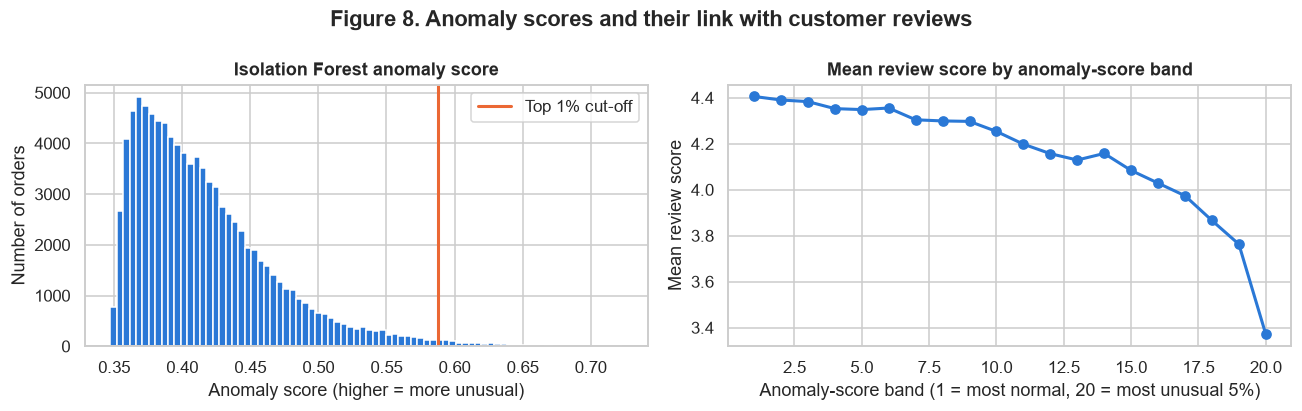

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(anomaly_data["iforest_score"], bins=80, color=COLOURS[0])
threshold_value = np.sort(anomaly_data["iforest_score"].values)[-n_review]
axes[0].axvline(threshold_value, color=COLOURS[1], linewidth=2, label="Top 1% cut-off")
axes[0].set_title("Isolation Forest anomaly score")
axes[0].set_xlabel("Anomaly score (higher = more unusual)")
axes[0].set_ylabel("Number of orders")
axes[0].legend()

score_bins = pd.qcut(anomaly_data["iforest_score"], 20, labels=False)
review_by_bin = anomaly_data.groupby(score_bins)["review_score"].mean()
axes[1].plot(range(1, 21), review_by_bin.values, marker="o", color=COLOURS[0], linewidth=2)
axes[1].set_title("Mean review score by anomaly-score band")
axes[1].set_xlabel("Anomaly-score band (1 = most normal, 20 = most unusual 5%)")
axes[1].set_ylabel("Mean review score")
fig.suptitle("Figure 8. Anomaly scores and their link with customer reviews", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig08_anomaly.png"))
plt.show()

Mean review score falls steadily as the anomaly score rises, and much more steeply in the top three bands (the most unusual 15% of orders).

# 7. Task 5: Predicting late delivery and delivery time
## 7.1 Problem formulation, decision points and leakage
Two related supervised problems are modelled:

* Classification: will this order arrive after its estimated date (is_late)?
* Regression: how many days will it take from purchase to delivery (delivery_days)?

A model is only useful if its inputs are known at the moment the prediction is made.

Evaluation design. Section 3.1 showed strong drift over time. We therefore use a temporal hold-out:
* training set: orders purchased January 2017 – March 2018,
* test set: orders purchased April – August 2018 (never used for any choice).
Hyperparameters are chosen with time-series cross-validation inside the training set (each fold trains on earlier months and validates on later ones), as recommended for time-ordered data


In [48]:
# Keep the 20 most common categories, group the rest as 'other' (fewer one-hot columns, less overfitting)
top_categories = delivery_data["main_category"].value_counts().index[:20]
delivery_data["category_group"] = np.where(delivery_data["main_category"].isin(top_categories),
                                           delivery_data["main_category"], "other")
for column in ["total_price", "total_freight", "total_weight_g", "distance_km"]:
    delivery_data["log_" + column] = np.log1p(delivery_data[column])

delivery_data["days_to_carrier"] = ((delivery_data["order_delivered_carrier_date"] -
                                     delivery_data["order_purchase_timestamp"]).dt.total_seconds() / 86400)
delivery_data["buffer_at_dispatch"] = ((delivery_data["order_estimated_delivery_date"] -
                                        delivery_data["order_delivered_carrier_date"]).dt.total_seconds() / 86400)

numeric_features = ["estimated_days", "log_distance_km", "same_state", "n_items", "n_sellers",
                    "log_total_price", "log_total_freight", "freight_ratio", "log_total_weight_g",
                    "installments", "purchase_dow", "purchase_hour"]
categorical_features = ["customer_state", "seller_state", "category_group", "payment_type"]
dispatch_features = numeric_features + ["days_to_carrier", "buffer_at_dispatch"]

train = delivery_data[delivery_data["order_purchase_timestamp"] < "2018-04-01"].copy()
test = delivery_data[delivery_data["order_purchase_timestamp"] >= "2018-04-01"].copy()

print(f"Training set: {len(train):,} orders, late rate {100 * train['is_late'].mean():.2f}%")
print(f"Test set:     {len(test):,} orders, late rate {100 * test['is_late'].mean():.2f}%")

Training set: 64,053 orders, late rate 7.98%
Test set:     32,150 orders, late rate 4.42%


The test period has a much lower late rate than the training period 

# 7.2 Checking multicollinearity
The variance inflation factor (VIF) measures how well each numeric feature is explained by the others. Values above 5–10 are a common warning sign.

In [49]:
vif_data = train[numeric_features].fillna(train[numeric_features].median())
vif_data = (vif_data - vif_data.mean()) / vif_data.std()
vif_data.insert(0, "constant", 1.0)
vif_rows = []
for i, feature in enumerate(vif_data.columns):
    if feature != "constant":
        vif_rows.append({"feature": feature, "VIF": variance_inflation_factor(vif_data.values, i)})
vif_table = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)
vif_table.to_csv(os.path.join(RESULTS_FOLDER, "task5_vif.csv"), index=False)
print(vif_table.to_string(index=False))

           feature   VIF
 log_total_freight 4.690
   log_total_price 4.485
     freight_ratio 3.319
   log_distance_km 2.771
        same_state 2.330
log_total_weight_g 2.019
    estimated_days 1.642
           n_items 1.495
      installments 1.210
         n_sellers 1.075
      purchase_dow 1.008
     purchase_hour 1.002


The highest VIFs come from the price–freight–freight-ratio group, which is expected, because the ratio is built from the other two. 

# 7.3 Classification at purchase: baselines and models
Metrics. With only a few per cent of orders late, accuracy is uninformative. We report:PR-AUC, the main metric, ROC-AUC, Brier score

Baselines. 
Prior (dummy) model, One-feature rule:

In [50]:
def make_preprocessor(numeric_columns, dense_output=False):
    # Numeric: fill gaps with the training median, then standardise.
    # Categorical: fill gaps with the most common value, then one-hot encode.
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())])
    categorical_steps = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=not dense_output))])
    return ColumnTransformer([("numeric", numeric_steps, numeric_columns),
                              ("categorical", categorical_steps, categorical_features)])


def classification_scores(y_true, probabilities):
    return {"ROC_AUC": roc_auc_score(y_true, probabilities),
            "PR_AUC": average_precision_score(y_true, probabilities),
            "Brier": brier_score_loss(y_true, probabilities)}


time_folds = TimeSeriesSplit(n_splits=4)   # train sorted by time: each fold validates on later months

classifier_candidates = {
    "Logistic regression": (LogisticRegression(max_iter=3000, class_weight="balanced"),
                            {"model__C": [0.01, 0.1, 1.0]}, False),
    "Decision tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_SEED),
                      {"model__max_depth": [4, 8, 12], "model__min_samples_leaf": [50, 200]}, False),
    "Random forest": (RandomForestClassifier(n_estimators=150, class_weight="balanced",
                                             random_state=RANDOM_SEED, n_jobs=-1),
                      {"model__max_depth": [8, 12], "model__min_samples_leaf": [20]}, False),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=RANDOM_SEED),
                          {"model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 6]}, True),
}


def tune_and_test_classifiers(feature_list, label):
    rows = []
    fitted = {}
    for name, (model, grid, needs_dense) in classifier_candidates.items():
        pipeline = Pipeline([("prep", make_preprocessor(feature_list, needs_dense)), ("model", model)])
        search = GridSearchCV(pipeline, grid, cv=time_folds, scoring="average_precision", n_jobs=1)
        search.fit(train[feature_list + categorical_features], train["is_late"])
        test_probabilities = search.predict_proba(test[feature_list + categorical_features])[:, 1]
        row = {"decision_point": label, "model": name, "best_params": str(search.best_params_),
               "CV_PR_AUC": search.best_score_}
        row.update(classification_scores(test["is_late"], test_probabilities))
        rows.append(row)
        fitted[name] = (search.best_estimator_, test_probabilities)
        print(f"  {name:<20} CV PR-AUC {search.best_score_:.3f} | test PR-AUC {row['PR_AUC']:.3f}, "
              f"ROC-AUC {row['ROC_AUC']:.3f}, Brier {row['Brier']:.4f}")
    return rows, fitted


# Baselines
baseline_rows = []
prior_model = DummyClassifier(strategy="prior").fit(train[numeric_features], train["is_late"])
prior_probabilities = prior_model.predict_proba(test[numeric_features])[:, 1]
row = {"decision_point": "purchase", "model": "Baseline: prior", "best_params": "", "CV_PR_AUC": np.nan}
row.update(classification_scores(test["is_late"], prior_probabilities))
baseline_rows.append(row)

# One-feature rule: shorter promised window = higher risk. We turn the rank into a 0-1 score.
rule_score = 1 - test["estimated_days"].rank(pct=True)
row = {"decision_point": "purchase", "model": "Baseline: short promise rule", "best_params": "", "CV_PR_AUC": np.nan}
row.update(classification_scores(test["is_late"], rule_score))
row["Brier"] = np.nan   # a rank is not a probability, so the Brier score is not meaningful
baseline_rows.append(row)

print("Purchase-time models:")
purchase_rows, purchase_models = tune_and_test_classifiers(numeric_features, "purchase")

Purchase-time models:
  Logistic regression  CV PR-AUC 0.171 | test PR-AUC 0.087, ROC-AUC 0.694, Brier 0.2499
  Decision tree        CV PR-AUC 0.146 | test PR-AUC 0.072, ROC-AUC 0.629, Brier 0.2524
  Random forest        CV PR-AUC 0.175 | test PR-AUC 0.073, ROC-AUC 0.627, Brier 0.2189
  Gradient boosting    CV PR-AUC 0.163 | test PR-AUC 0.081, ROC-AUC 0.635, Brier 0.0451


## 7.4 Classification at dispatch
At hand-over to the carrier, Olist knows how long the seller took and how much of the promised window remains. We repeat the same procedure with these two extra features. The matching one-feature baseline ranks orders by the remaining buffer (less buffer = higher risk).

In [51]:
row = {"decision_point": "dispatch", "model": "Baseline: prior", "best_params": "", "CV_PR_AUC": np.nan}
row.update(classification_scores(test["is_late"], prior_probabilities))
baseline_rows.append(row)

buffer_filled = test["buffer_at_dispatch"].fillna(train["buffer_at_dispatch"].median())
buffer_rule_score = 1 - buffer_filled.rank(pct=True)
row = {"decision_point": "dispatch", "model": "Baseline: remaining buffer rule", "best_params": "", "CV_PR_AUC": np.nan}
row.update(classification_scores(test["is_late"], buffer_rule_score))
row["Brier"] = np.nan
baseline_rows.append(row)

print("Dispatch-time models:")
dispatch_rows, dispatch_models = tune_and_test_classifiers(dispatch_features, "dispatch")

classification_results = pd.DataFrame(baseline_rows[:2] + purchase_rows + baseline_rows[2:] + dispatch_rows)
classification_results.to_csv(os.path.join(RESULTS_FOLDER, "task5_classification_results.csv"), index=False)
classification_results[["decision_point", "model", "CV_PR_AUC", "PR_AUC", "ROC_AUC", "Brier", "best_params"]]

Dispatch-time models:
  Logistic regression  CV PR-AUC 0.309 | test PR-AUC 0.227, ROC-AUC 0.799, Brier 0.2128
  Decision tree        CV PR-AUC 0.270 | test PR-AUC 0.261, ROC-AUC 0.774, Brier 0.2163
  Random forest        CV PR-AUC 0.303 | test PR-AUC 0.250, ROC-AUC 0.790, Brier 0.2024
  Gradient boosting    CV PR-AUC 0.312 | test PR-AUC 0.361, ROC-AUC 0.813, Brier 0.0366


,decision_point,model,CV_PR_AUC,PR_AUC,ROC_AUC,Brier,best_params
0,purchase,Baseline: prior,NaN,0.044,0.500,0.044,
1,purchase,Baseline: short promise rule,NaN,0.093,0.631,NaN,
2,purchase,Logistic regression,0.171,0.087,0.694,0.250,{'model__C': 0.01}
3,purchase,Decision tree,0.146,0.072,0.629,0.252,"{'model__max_depth': 8, 'model__min_samples_le..."
4,purchase,Random forest,0.175,0.073,0.627,0.219,"{'model__max_depth': 12, 'model__min_samples_l..."
5,purchase,Gradient boosting,0.163,0.081,0.635,0.045,"{'model__learning_rate': 0.05, 'model__max_dep..."
6,dispatch,Baseline: prior,NaN,0.044,0.500,0.044,
7,dispatch,Baseline: remaining buffer rule,NaN,0.305,0.700,NaN,
8,dispatch,Logistic regression,0.309,0.227,0.799,0.213,{'model__C': 0.01}
9,dispatch,Decision tree,0.270,0.261,0.774,0.216,"{'model__max_depth': 8, 'model__min_samples_le..."


*At purchase, every model beats the prior baseline, but only modestly, and none beats the one-feature "short promise" rule on PR-AUC.
*At dispatch, each model's test PR-AUC is 2.6 to 4.1 times its purchase-time value. Once the seller's handling time is known, lateness becomes much more predictable
*The Brier scores of the class-weighted models are much worse than the prior model's.

# 7.5 Robustness checks for the classifier
We check five things; (a) how much a random split would have overstated performance; (b) the effect of class weighting on ranking and calibration; (c) the stricter definition of lateness; (d) sensitivity to the random seed; and (e) which months the model gets wrong.

In [52]:
robustness_rows = []
purchase_columns = numeric_features + categorical_features

# (a) Random split instead of temporal split
random_train, random_test = train_test_split(delivery_data, test_size=0.33, stratify=delivery_data["is_late"],
                                             random_state=RANDOM_SEED)
lr_pipeline = Pipeline([("prep", make_preprocessor(numeric_features)),
                        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", C=0.01))])
lr_pipeline.fit(random_train[purchase_columns], random_train["is_late"])
random_probabilities = lr_pipeline.predict_proba(random_test[purchase_columns])[:, 1]
row = {"check": "(a) random 67/33 split instead of temporal", "model": "Logistic regression"}
row.update(classification_scores(random_test["is_late"], random_probabilities))
robustness_rows.append(row)

# (b) Logistic regression with and without class weighting (temporal split)
for weighting in ["balanced", None]:
    pipeline = Pipeline([("prep", make_preprocessor(numeric_features)),
                         ("model", LogisticRegression(max_iter=3000, class_weight=weighting, C=0.01))])
    pipeline.fit(train[purchase_columns], train["is_late"])
    probabilities = pipeline.predict_proba(test[purchase_columns])[:, 1]
    row = {"check": f"(b) class_weight = {weighting}", "model": "Logistic regression"}
    row.update(classification_scores(test["is_late"], probabilities))
    robustness_rows.append(row)
    if weighting is None:
        unweighted_probabilities = probabilities
    else:
        weighted_probabilities = probabilities

# (c) late if delivered after midnight at the start of the estimated date
strict_train_target = (train["order_delivered_customer_date"] > train["order_estimated_delivery_date"]).astype(int)
strict_test_target = (test["order_delivered_customer_date"] > test["order_estimated_delivery_date"]).astype(int)
pipeline = Pipeline([("prep", make_preprocessor(numeric_features)),
                     ("model", LogisticRegression(max_iter=3000, class_weight="balanced", C=0.01))])
pipeline.fit(train[purchase_columns], strict_train_target)
probabilities = pipeline.predict_proba(test[purchase_columns])[:, 1]
row = {"check": f"(c) strict timestamp definition (test late rate {100 * strict_test_target.mean():.1f}%)",
       "model": "Logistic regression"}
row.update(classification_scores(strict_test_target, probabilities))
robustness_rows.append(row)

# (d) Seed sensitivity of the random forest (purchase time, best settings)
best_forest = purchase_models["Random forest"][0]
for seed in [1, 2, 3]:
    forest_copy = Pipeline([("prep", make_preprocessor(numeric_features)),
                            ("model", RandomForestClassifier(n_estimators=150, class_weight="balanced", n_jobs=-1,
                                                             max_depth=best_forest.named_steps["model"].max_depth,
                                                             min_samples_leaf=20, random_state=seed))])
    forest_copy.fit(train[purchase_columns], train["is_late"])
    probabilities = forest_copy.predict_proba(test[purchase_columns])[:, 1]
    row = {"check": f"(d) random forest, seed {seed}", "model": "Random forest"}
    row.update(classification_scores(test["is_late"], probabilities))
    robustness_rows.append(row)

classification_robustness = pd.DataFrame(robustness_rows)
classification_robustness.to_csv(os.path.join(RESULTS_FOLDER, "task5_classification_robustness.csv"), index=False)
classification_robustness

,check,model,ROC_AUC,PR_AUC,Brier
0,(a) random 67/33 split instead of temporal,Logistic regression,0.712,0.150,0.218
1,(b) class_weight = balanced,Logistic regression,0.694,0.087,0.250
2,(b) class_weight = None,Logistic regression,0.686,0.087,0.046
3,(c) strict timestamp definition (test late rat...,Logistic regression,0.702,0.117,0.253
4,"(d) random forest, seed 1",Random forest,0.629,0.072,0.220
5,"(d) random forest, seed 2",Random forest,0.637,0.074,0.220
6,"(d) random forest, seed 3",Random forest,0.639,0.073,0.220


(a) A random split gives a clearly higher PR-AUC than the temporal split. 
(b) Class weighting barely changes the ranking (ROC-AUC and PR-AUC are similar), but it badly damages calibration (much higher Brier score). 
(c) The stricter definition raises the late rate but leaves the conclusions unchanged.
(d) Random-forest results vary only slightly with the seed, so model differences larger than that are not due to chance initialisation.

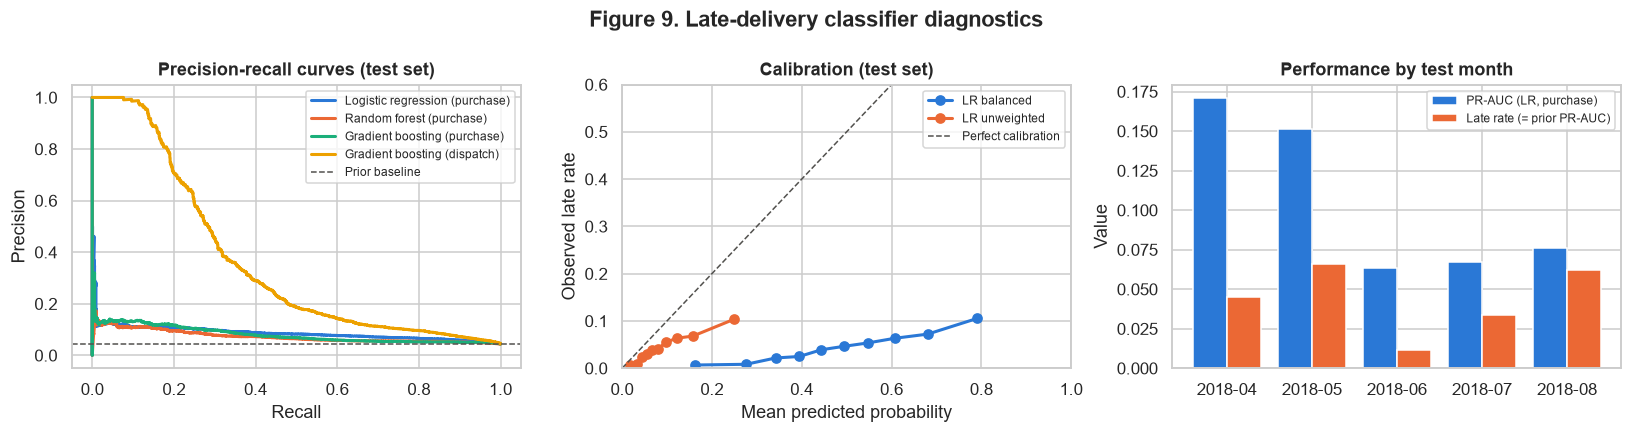

     month  late_rate  PR_AUC
0  2018-04      0.045   0.171
1  2018-05      0.066   0.151
2  2018-06      0.012   0.063
3  2018-07      0.034   0.067
4  2018-08      0.062   0.076


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for name, colour in zip(["Logistic regression", "Random forest", "Gradient boosting"], COLOURS[:3]):
    precision, recall, _ = precision_recall_curve(test["is_late"], purchase_models[name][1])
    axes[0].plot(recall, precision, color=colour, linewidth=2, label=f"{name} (purchase)")
precision, recall, _ = precision_recall_curve(test["is_late"], dispatch_models["Gradient boosting"][1])
axes[0].plot(recall, precision, color=COLOURS[3], linewidth=2, label="Gradient boosting (dispatch)")
axes[0].axhline(test["is_late"].mean(), color="#52514e", linestyle="--", linewidth=1, label="Prior baseline")
axes[0].set_title("Precision-recall curves (test set)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(fontsize=8)

for probabilities, name, colour in [(weighted_probabilities, "LR balanced", COLOURS[0]),
                                    (unweighted_probabilities, "LR unweighted", COLOURS[1])]:
    observed, predicted = calibration_curve(test["is_late"], probabilities, n_bins=10, strategy="quantile")
    axes[1].plot(predicted, observed, marker="o", color=colour, linewidth=2, label=name)
axes[1].plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1, label="Perfect calibration")
axes[1].set_title("Calibration (test set)")
axes[1].set_xlabel("Mean predicted probability")
axes[1].set_ylabel("Observed late rate")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 0.6)
axes[1].legend(fontsize=8)

test_month = test["order_purchase_timestamp"].dt.to_period("M").astype(str)
month_rows = []
for month in sorted(test_month.unique()):
    in_month = test_month == month
    month_rows.append({"month": month, "late_rate": test.loc[in_month, "is_late"].mean(),
                       "PR_AUC": average_precision_score(test.loc[in_month, "is_late"],
                                                         purchase_models["Logistic regression"][1][in_month.values])})
month_performance = pd.DataFrame(month_rows)
x_positions = np.arange(len(month_performance))
axes[2].bar(x_positions - 0.2, month_performance["PR_AUC"], width=0.4, color=COLOURS[0], label="PR-AUC (LR, purchase)")
axes[2].bar(x_positions + 0.2, month_performance["late_rate"], width=0.4, color=COLOURS[1], label="Late rate (= prior PR-AUC)")
axes[2].set_xticks(x_positions)
axes[2].set_xticklabels(month_performance["month"])
axes[2].set_title("Performance by test month")
axes[2].set_ylabel("Value")
axes[2].legend(fontsize=8)

fig.suptitle("Figure 9. Late-delivery classifier diagnostics", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig09_classifier_diagnostics.png"))
plt.show()
month_performance.to_csv(os.path.join(RESULTS_FOLDER, "task5_month_performance.csv"), index=False)
print(month_performance)

The precision–recall curves of the purchase-time models lie only a little above the prior line, whereas the dispatch-time model achieves high precision for the first 10–20% of recall.

# 7.6 What the purchase-time model sees: alert budget and permutation importance
Permutation importance measures how much test PR-AUC drops when one feature is randomly shuffled, which breaks its link with the outcome.

In [54]:
budget_rows = []
for label, models in [("purchase", purchase_models), ("dispatch", dispatch_models)]:
    for name in ["Logistic regression", "Gradient boosting"]:
        probabilities = models[name][1]
        for budget in [0.05, 0.10, 0.20]:
            n_alerts = int(budget * len(test))
            alert_rows = np.argsort(-probabilities)[:n_alerts]
            predicted_late = np.zeros(len(test), dtype=int)
            predicted_late[alert_rows] = 1
            tn, fp, fn, tp = confusion_matrix(test["is_late"], predicted_late).ravel()
            budget_rows.append({"decision_point": label, "model": name, "alert_budget_%": 100 * budget,
                                "precision": tp / (tp + fp), "recall": tp / (tp + fn),
                                "lift_over_random": (tp / (tp + fp)) / test["is_late"].mean()})
alert_budget = pd.DataFrame(budget_rows)
alert_budget.to_csv(os.path.join(RESULTS_FOLDER, "task5_alert_budget.csv"), index=False)
print(alert_budget.to_string(index=False))

importance_model = purchase_models["Logistic regression"][0]
importance = permutation_importance(importance_model, test[purchase_columns], test["is_late"],
                                    scoring="average_precision", n_repeats=5, random_state=RANDOM_SEED)
importance_table = pd.DataFrame({"feature": purchase_columns,
                                 "mean_drop_in_PR_AUC": importance.importances_mean,
                                 "std": importance.importances_std}).sort_values("mean_drop_in_PR_AUC", ascending=False)
importance_table.to_csv(os.path.join(RESULTS_FOLDER, "task5_permutation_importance.csv"), index=False)
print()
print(importance_table.to_string(index=False))

decision_point               model  alert_budget_%  precision  recall  lift_over_random
      purchase Logistic regression           5.000      0.109   0.123             2.464
      purchase Logistic regression          10.000      0.105   0.239             2.386
      purchase Logistic regression          20.000      0.089   0.402             2.009
      purchase   Gradient boosting           5.000      0.124   0.141             2.816
      purchase   Gradient boosting          10.000      0.105   0.237             2.372
      purchase   Gradient boosting          20.000      0.082   0.370             1.851
      dispatch Logistic regression           5.000      0.227   0.257             5.139
      dispatch Logistic regression          10.000      0.178   0.403             4.032
      dispatch Logistic regression          20.000      0.132   0.595             2.977
      dispatch   Gradient boosting           5.000      0.327   0.370             7.406
      dispatch   Gradient boosti

At a 10% alert budget, the purchase-time model's alerts are late roughly two to three times as often as randomly chosen orders. Most late orders are still missed, which is too weak to promise individual customers anything.

# 7.7 Regression: predicting delivery days
Baselines. (1) The training median for every order. (2) Olist's own estimate, used as a prediction. (3) Olist's estimate recalibrated by a one-variable linear regression, which removes the deliberate safety margin.

Models. Ridge regression on the raw target and on log(1 + days); random forest; gradient boosting with a log target. The target is right-skewed (Figure 2), so modelling its logarithm reduces the influence of a few very long deliveries and fits multiplicative effects. This is a standard variance-stabilising transformation.

Metrics. MAE (average error in days, easy to explain), RMSE (penalises large errors more), R² and mean bias (mean of predicted minus actual), which shows systematic over- or under-prediction.


In [55]:
def regression_scores(y_true, predictions):
    return {"MAE": mean_absolute_error(y_true, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
            "R2": r2_score(y_true, predictions),
            "mean_bias": np.mean(predictions - y_true)}


regression_rows = []
y_train_days = train["delivery_days"]
y_test_days = test["delivery_days"]

row = {"model": "Baseline: training median"}
row.update(regression_scores(y_test_days, np.full(len(test), y_train_days.median())))
regression_rows.append(row)

row = {"model": "Baseline: Olist estimate (raw)"}
row.update(regression_scores(y_test_days, test["estimated_days"]))
regression_rows.append(row)

recalibration = LinearRegression().fit(train[["estimated_days"]], y_train_days)
row = {"model": "Baseline: Olist estimate recalibrated"}
row.update(regression_scores(y_test_days, recalibration.predict(test[["estimated_days"]])))
regression_rows.append(row)

regressor_candidates = {
    "Ridge (raw target)": (Ridge(), {"model__alpha": [0.1, 1.0, 10.0]}, False),
    "Ridge (log target)": (TransformedTargetRegressor(regressor=Ridge(), func=np.log1p, inverse_func=np.expm1),
                           {"model__regressor__alpha": [0.1, 1.0, 10.0]}, False),
    "Random forest": (RandomForestRegressor(n_estimators=150, min_samples_leaf=20, random_state=RANDOM_SEED, n_jobs=-1),
                      {"model__max_depth": [8, 12]}, False),
    "Gradient boosting (log target)": (TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(random_state=RANDOM_SEED), func=np.log1p, inverse_func=np.expm1),
        {"model__regressor__learning_rate": [0.05, 0.1], "model__regressor__max_depth": [3, 6]}, True),
}

regression_predictions = {}
for name, (model, grid, needs_dense) in regressor_candidates.items():
    pipeline = Pipeline([("prep", make_preprocessor(numeric_features, needs_dense)), ("model", model)])
    search = GridSearchCV(pipeline, grid, cv=time_folds, scoring="neg_mean_absolute_error", n_jobs=1)
    search.fit(train[purchase_columns], y_train_days)
    predictions = search.predict(test[purchase_columns])
    regression_predictions[name] = (search.best_estimator_, predictions)
    row = {"model": name, "CV_MAE": -search.best_score_}
    row.update(regression_scores(y_test_days, predictions))
    regression_rows.append(row)
    print(f"{name:<32} CV MAE {-search.best_score_:.2f} | test MAE {row['MAE']:.2f}, R2 {row['R2']:.3f}")

regression_results = pd.DataFrame(regression_rows)
regression_results.to_csv(os.path.join(RESULTS_FOLDER, "task5_regression_results.csv"), index=False)
regression_results

Ridge (raw target)               CV MAE 5.44 | test MAE 5.34, R2 0.041
Ridge (log target)               CV MAE 5.52 | test MAE 4.54, R2 0.201
Random forest                    CV MAE 5.45 | test MAE 5.50, R2 -0.010
Gradient boosting (log target)   CV MAE 5.46 | test MAE 4.55, R2 0.200


,model,MAE,RMSE,R2,mean_bias,CV_MAE
0,Baseline: training median,5.542,7.325,-0.064,1.801,NaN
1,Baseline: Olist estimate (raw),12.777,15.214,-3.592,12.025,NaN
2,Baseline: Olist estimate recalibrated,5.405,7.182,-0.023,2.796,NaN
3,Ridge (raw target),5.339,6.952,0.041,3.186,5.442
4,Ridge (log target),4.536,6.346,0.201,1.766,5.518
5,Random forest,5.500,7.134,-0.010,3.457,5.455
6,Gradient boosting (log target),4.550,6.352,0.200,1.861,5.465


Olist's raw estimate is a poor point prediction (it overstates delivery time by about 12 days on average), because it is deliberately conservative. Once recalibrated, it becomes a reasonable baseline.

# 7.8 Residual diagnostics

Model selected by cross-validated MAE: Ridge (raw target)


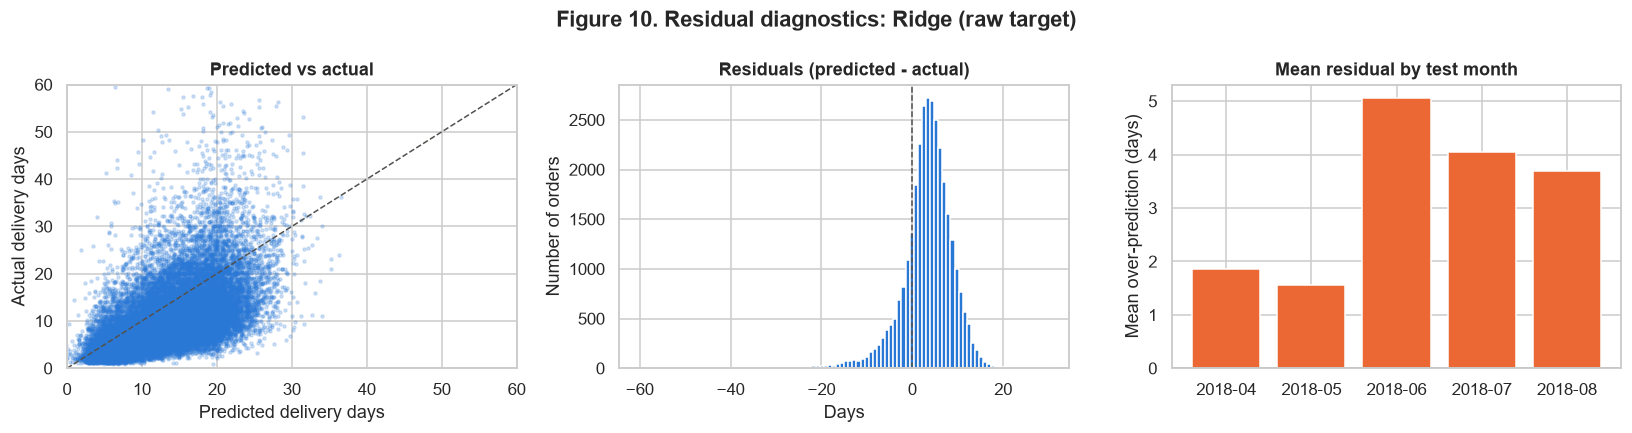

         Ridge (raw target)  Ridge (log target)
2018-04               1.860               0.340
2018-05               1.570               0.150
2018-06               5.060               3.610
2018-07               4.060               2.560
2018-08               3.690               2.470
Skewness of residuals (Ridge (raw target)): -2.80


In [56]:
# Choose the model by cross-validated MAE (training data only), never by test MAE
best_regression_name = regression_results.dropna(subset=["CV_MAE"]).sort_values("CV_MAE").iloc[0]["model"]
comparison_regression_name = "Ridge (log target)"
best_predictions = regression_predictions[best_regression_name][1]
residuals = best_predictions - y_test_days.values
print("Model selected by cross-validated MAE:", best_regression_name)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(best_predictions, y_test_days, s=4, alpha=0.2, color=COLOURS[0])
axes[0].plot([0, 60], [0, 60], color="#52514e", linestyle="--", linewidth=1)
axes[0].set_xlim(0, 60)
axes[0].set_ylim(0, 60)
axes[0].set_title("Predicted vs actual")
axes[0].set_xlabel("Predicted delivery days")
axes[0].set_ylabel("Actual delivery days")

axes[1].hist(residuals, bins=100, range=(-60, 30), color=COLOURS[0])
axes[1].axvline(0, color="#52514e", linestyle="--", linewidth=1)
axes[1].set_title("Residuals (predicted - actual)")
axes[1].set_xlabel("Days")
axes[1].set_ylabel("Number of orders")

residual_by_month = pd.Series(residuals).groupby(test_month.values).mean()
comparison_residuals = regression_predictions[comparison_regression_name][1] - y_test_days.values
comparison_by_month = pd.Series(comparison_residuals).groupby(test_month.values).mean()
axes[2].bar(residual_by_month.index, residual_by_month.values, color=COLOURS[1])
axes[2].axhline(0, color="#52514e", linewidth=1)
axes[2].set_title("Mean residual by test month")
axes[2].set_ylabel("Mean over-prediction (days)")

fig.suptitle(f"Figure 10. Residual diagnostics: {best_regression_name}", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_FOLDER, "fig10_regression_residuals.png"))
plt.show()
print(pd.DataFrame({best_regression_name: residual_by_month, comparison_regression_name: comparison_by_month}).round(2))
print(f"Skewness of residuals ({best_regression_name}): {stats.skew(residuals):.2f}")

The predictions are compressed towards the middle: very long deliveries are under predicted (the long left tail of residuals, skewness about −2.8) and short ones are over predicted.

## 7.9 Robustness: does monthly retraining remove the bias?
We simulate how the model would be used in practice.

In [57]:
retrain_rows = []
for model_name in [best_regression_name, comparison_regression_name]:
    all_predictions = []
    all_actuals = []
    model_template = regression_predictions[model_name][0]
    for month in pd.period_range("2018-04", "2018-08", freq="M"):
        month_start = month.start_time
        month_end = (month + 1).start_time
        # train only on orders already delivered before the month starts (no future information)
        known_data = delivery_data[delivery_data["order_delivered_customer_date"] < month_start]
        month_data = delivery_data[(delivery_data["order_purchase_timestamp"] >= month_start) &
                                   (delivery_data["order_purchase_timestamp"] < month_end)]
        monthly_model = clone(model_template)
        monthly_model.fit(known_data[purchase_columns], known_data["delivery_days"])
        predictions = monthly_model.predict(month_data[purchase_columns])
        all_predictions.extend(predictions)
        all_actuals.extend(month_data["delivery_days"])
        row = {"model": model_name, "month": str(month), "training_orders": len(known_data),
               "test_orders": len(month_data)}
        row.update(regression_scores(month_data["delivery_days"], predictions))
        retrain_rows.append(row)
    row = {"model": model_name, "month": "Overall", "training_orders": np.nan, "test_orders": len(all_actuals)}
    row.update(regression_scores(np.array(all_actuals), np.array(all_predictions)))
    retrain_rows.append(row)

monthly_retraining = pd.DataFrame(retrain_rows)
monthly_retraining.to_csv(os.path.join(RESULTS_FOLDER, "task5_monthly_retraining.csv"), index=False)
monthly_retraining

,model,month,training_orders,test_orders,MAE,RMSE,R2,mean_bias
0,Ridge (raw target),2018-04,"60,201.000",6798,4.677,6.894,0.347,1.194
1,Ridge (raw target),2018-05,"68,051.000",6749,5.019,6.806,0.278,1.219
2,Ridge (raw target),2018-06,"75,162.000",6096,5.751,7.272,-0.211,4.479
3,Ridge (raw target),2018-07,"81,991.000",6156,5.184,6.595,-0.131,3.489
4,Ridge (raw target),2018-08,"87,830.000",6351,4.166,5.256,-0.469,2.857
5,Ridge (raw target),Overall,NaN,32150,4.949,6.602,0.135,2.590
6,Ridge (log target),2018-04,"60,201.000",6798,4.304,6.848,0.355,-0.131
7,Ridge (log target),2018-05,"68,051.000",6749,4.679,6.718,0.297,-0.122
8,Ridge (log target),2018-06,"75,162.000",6096,4.788,6.533,0.022,3.132
9,Ridge (log target),2018-07,"81,991.000",6156,4.203,5.767,0.135,1.951


Monthly retraining improves both models
MAE falls from 5.33 to 4.95 days for the selected ridge model and from 4.53 to 4.25 days for the log-target comparison and R² rises for both

## 7.10 Linking the regression and the classification

In [ ]:
gap_rows = []
for model_name in [best_regression_name, comparison_regression_name]:
    gap_score = regression_predictions[model_name][1] - test["estimated_days"].values
    # This score is in days, not a probability, so only the ranking metrics are meaningful
    gap_rows.append({"model": f"Gap score from {model_name}",
                     "ROC_AUC": roc_auc_score(test["is_late"], gap_score),
                     "PR_AUC": average_precision_score(test["is_late"], gap_score)})
gap_results = pd.DataFrame(gap_rows)
print(gap_results.to_string(index=False))
best_purchase_classifier = classification_results[classification_results["decision_point"] == "purchase"].sort_values(
    "PR_AUC", ascending=False).iloc[0]
print(f"Best purchase-time classifier ({best_purchase_classifier['model']}): "
      f"ROC-AUC {best_purchase_classifier['ROC_AUC']:.3f}, PR-AUC {best_purchase_classifier['PR_AUC']:.3f}")
gap_results.to_csv(os.path.join(RESULTS_FOLDER, "task5_gap_score.csv"), index=False)

The regression-derived score ranks late orders better than every dedicated purchase-time classifier and baseline, on both ROC-AUC and PR-AUC, whichever regression model is used.